# Spatial Void Feature Extraction — X-ray Pipeline

Extracts location-aware void features from the hellastudy X-ray images for the ChipVoid-Thermal classification project.

**Pipeline (follows Part I of the hellastudy, §IV.A, Fig. 5 — "average image subtracted from the DUT, then thresholding"):**
1. Group X-ray images by LED type.
2. Per LED type → **register** all images (shift, rotation, scale) and build a void-less *reference image* (median of the registered images).
3. Auto-detect pad regions from the reference (pads are the darkest connected components). The largest-area component is the thermal pad for 3-pad LEDs; 2-pad LEDs have no thermal pad.
4. For each DUT, fit the reference to the DUT **locally** (brightness, contrast, sub-pixel shift, blur) and subtract → residual where voids are highlighted and internal structure is suppressed. Hysteresis threshold → binary void mask.
5. Validate the void ratio of every LED against the paper's own result, `data/raw/CrackVoid Ratios/Xray Void Ratio.csv`.
6. Compute spatial features per pad, in pad-normalized coordinates. Aggregate by pad role (thermal vs. electrical).

**Data:** `../data/raw/XRay/XRay/<LED_TYPE>/XRay_<LED_TYPE>_<PASTE>_Panel<N>_LED<NN>_<TSC>TSC.jpg`. 200 images per LED type × 9 types = 1,800 total, all at 0 TSC (initial inspection). Six of them are placeholder pictures that only say "Missing".

**Modality:** X-ray only. SAM is not required for initial void characterization (Part I: *"SAM is less sensitive for initial void detection than X-ray"*).

In [1]:
import os
import re
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.stats import skew as _scipy_skew
from skimage.measure import label, regionprops

np.random.seed(42)
plt.rcParams["figure.dpi"] = 110

DATA_DIR = Path(r"../data/raw/XRay/XRay").resolve()
assert DATA_DIR.is_dir(), f"Data directory not found: {DATA_DIR}"
LED_TYPES = sorted([p.name for p in DATA_DIR.iterdir() if p.is_dir()])
print(f"Data: {DATA_DIR}")
print(f"LED types: {LED_TYPES}")

Data: C:\Users\JPagtalu\Documents\Joanna\MEng AI\ai221\ai221_project\data\raw\XRay\XRay
LED types: ['FC-GB1', 'FC-GB2', 'FC-GB3', 'FC-SP1', 'FC-SP2', 'FC-SP3', 'FC-SP4', 'VTF1', 'VTF2']


## 1. Data loading

Images are JPEGs, mostly RGB — convert to grayscale on load. Image dimensions vary by LED type (200×200 up to 300×300) but are **consistent within a type**, which is all that matters for reference-image averaging.

Filename example: `XRay_FC-SP3_SAC105_Panel1_LED01_0000TSC.jpg` → metadata parsed into (`led_type`, `paste`, `panel`, `led_num`, `tsc`).

In [2]:
_FNAME_RE = re.compile(
    r"XRay_(?P<led_type>[^_]+)_(?P<paste>[^_]+)_Panel(?P<panel>\d+)_LED(?P<led_num>\d+)_(?P<tsc>\d+)TSC\.jpg",
    re.IGNORECASE,
)


def parse_filename(fname):
    m = _FNAME_RE.match(fname)
    if not m:
        return None
    d = m.groupdict()
    d["panel"]    = int(d["panel"])
    d["led_num"]  = int(d["led_num"])
    d["tsc"]      = int(d["tsc"])
    d["unit_id"]  = f"{d['led_type']}_{d['paste']}_P{d['panel']}_L{d['led_num']:02d}"
    return d


def load_led_type(led_type, tsc=0):
    """Load all images for one LED type at a given TSC. Returns (images, metadata_rows)."""
    folder = DATA_DIR / led_type
    images, meta = [], []
    for f in sorted(folder.iterdir()):
        info = parse_filename(f.name)
        if info is None or info["tsc"] != tsc:
            continue
        im = cv2.imread(str(f), cv2.IMREAD_GRAYSCALE)
        if im is None:
            continue
        images.append(im)
        info["file"] = f.name
        meta.append(info)
    return images, meta


# Smoke test on one LED type
images, meta = load_led_type("FC-SP3")
print(f"Loaded {len(images)} FC-SP3 images at TSC=0, example dims={images[0].shape}")
pd.DataFrame(meta).head()

Loaded 200 FC-SP3 images at TSC=0, example dims=(260, 220)


,led_type,paste,panel,led_num,tsc,unit_id,file
0,FC-SP3,SAC105,1,1,0,FC-SP3_SAC105_P1_L01,XRay_FC-SP3_SAC105_Panel1_LED01_0000TSC.jpg
1,FC-SP3,SAC105,1,2,0,FC-SP3_SAC105_P1_L02,XRay_FC-SP3_SAC105_Panel1_LED02_0000TSC.jpg
2,FC-SP3,SAC105,1,3,0,FC-SP3_SAC105_P1_L03,XRay_FC-SP3_SAC105_Panel1_LED03_0000TSC.jpg
3,FC-SP3,SAC105,1,4,0,FC-SP3_SAC105_P1_L04,XRay_FC-SP3_SAC105_Panel1_LED04_0000TSC.jpg
4,FC-SP3,SAC105,1,5,0,FC-SP3_SAC105_P1_L05,XRay_FC-SP3_SAC105_Panel1_LED05_0000TSC.jpg


## 2. Per-LED-type reference image (Part I method)

Each LED type gets its **own** reference image, computed from only that type's 200 units:

1. Skip placeholder pictures ("Missing").
2. Register every image to a template: full-range template search (some LEDs sit tens of pixels off-centre) → ECC refinement for shift + rotation → ECC affine for scale (magnification differs by about ±1.5 % between shots).
3. Reference = per-pixel **median** of the registered images; repeat the registration against that median.

**Why this matters:** a translation-only alignment that gives up beyond 8 px leaves pad edges and internal structures misaligned by a few pixels. After subtraction those edges are brighter than the reference and get counted as voids.

**What the reference should look like:** pads, bumps and wire bonds sharp; voids gone (they are at random places, so the median removes them).

placeholder ('Missing') images: 0,  lowest match score: 0.96


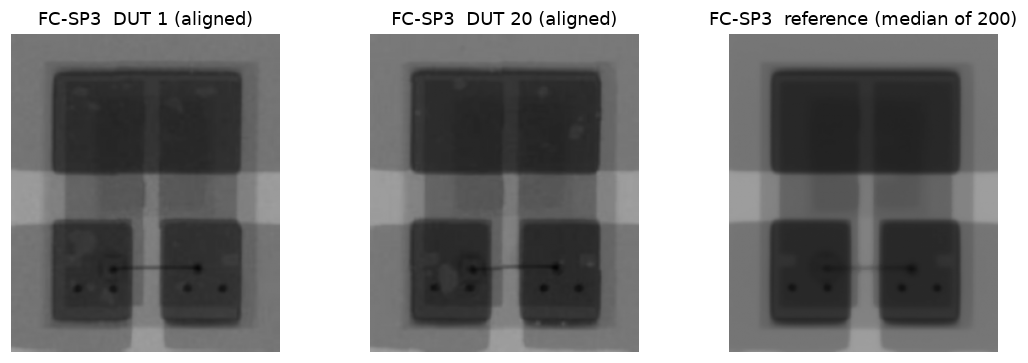

In [3]:
def is_placeholder(img):
    """Some files are not X-rays but a white picture with the word 'Missing'. They must not enter the reference."""
    return (img >= 250).mean() > 0.6


def _coarse_shift(img, tmpl, box, search=60):
    """Full-range translation search: where does the central crop of the template sit in img?"""
    x0, y0, x1, y1 = box
    padded = cv2.copyMakeBorder(img, search, search, search, search, cv2.BORDER_REPLICATE)
    res = cv2.matchTemplate(padded, tmpl[y0:y1, x0:x1], cv2.TM_CCOEFF_NORMED)
    _, score, _, loc = cv2.minMaxLoc(res)
    return loc[0] - search - x0, loc[1] - search - y0, score


def register_image(img, tmpl, box, affine=True):
    """Align img to tmpl. Coarse template search -> ECC (shift + rotation) -> ECC affine (also scale: the
    magnification differs by about +-1.5 % between shots). Returns (aligned, valid, score); valid = 1 where
    the aligned pixel really came from inside the original frame."""
    img, tmpl = img.astype(np.float32), tmpl.astype(np.float32)
    dx, dy, score = _coarse_shift(img, tmpl, box)
    warp = np.float32([[1, 0, dx], [0, 1, dy]])
    crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 80, 1e-6)
    try:
        _, warp = cv2.findTransformECC(tmpl, img, warp, cv2.MOTION_EUCLIDEAN, crit, None, 5)
    except cv2.error:
        pass
    if affine:
        try:
            _, w2 = cv2.findTransformECC(tmpl, img, warp.copy(), cv2.MOTION_AFFINE, crit, None, 5)
            sx, sy = np.hypot(w2[0, 0], w2[1, 0]), np.hypot(w2[0, 1], w2[1, 1])
            if 0.94 < sx < 1.06 and 0.94 < sy < 1.06:      # sanity limits on the scale
                warp = w2
        except cv2.error:
            pass
    size, flags = tmpl.shape[::-1], cv2.INTER_LINEAR + cv2.WARP_INVERSE_MAP
    out = cv2.warpAffine(img, warp, size, flags=flags, borderMode=cv2.BORDER_REPLICATE)
    valid = cv2.warpAffine(np.ones(img.shape, np.float32), warp, size, flags=flags,
                           borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    return out, (valid > 0.999).astype(np.uint8), score


_REG_CACHE = {}


def register_led_type(images, n_pass=3, led_type=None):
    """Register all images of one LED type to a common frame and build the void-less reference.

    Pass 1 aligns to the first real image, later passes align to the MEDIAN of the previous pass
    (the median ignores voids and outliers better than the mean). The last pass also fits scale.
    Returns dict(aligned (N,H,W) float32, valid (N,H,W) uint8, ok (N,) bool, score, reference float32).
    """
    key = (led_type, images[0].shape, len(images))
    if key in _REG_CACHE:
        return _REG_CACHE[key]
    ok = np.array([not is_placeholder(im) for im in images])
    smooth = [cv2.GaussianBlur(im.astype(np.float32), (0, 0), 0.8) for im in images]
    tmpl = cv2.GaussianBlur(images[int(np.argmax(ok))].astype(np.float32), (0, 0), 1.0)
    h, w = tmpl.shape
    box = (int(0.12 * w), int(0.12 * h), int(0.88 * w), int(0.88 * h))
    for it in range(n_pass):
        res = [register_image(s, tmpl, box, affine=(it == n_pass - 1)) for s in smooth]
        stack = np.stack([r[0] for r in res])
        score = np.array([r[2] for r in res])
        tmpl = np.median(stack[ok & (score > 0.5)], axis=0).astype(np.float32)
    out = dict(aligned=stack, valid=np.stack([r[1] for r in res]), ok=ok, score=score, reference=tmpl)
    _REG_CACHE[key] = out
    return out


def compute_reference(images):
    """Kept for the cells below: returns (reference uint8, list of aligned uint8 images)."""
    reg = register_led_type(images)
    ref = np.clip(reg["reference"], 0, 255).astype(np.uint8)
    return ref, [np.clip(a, 0, 255).astype(np.uint8) for a in reg["aligned"]]


# FC-SP3 DUT vs. reference (close-up sanity check)
reference, aligned = compute_reference(images)
reg_demo = register_led_type(images)
print(f"placeholder ('Missing') images: {int((~reg_demo['ok']).sum())},  lowest match score: {reg_demo['score'][reg_demo['ok']].min():.2f}")
fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
ax[0].imshow(aligned[0],  cmap="gray", vmin=0, vmax=255); ax[0].set_title("FC-SP3  DUT 1 (aligned)")
ax[1].imshow(aligned[20], cmap="gray", vmin=0, vmax=255); ax[1].set_title("FC-SP3  DUT 20 (aligned)")
ax[2].imshow(reference,  cmap="gray", vmin=0, vmax=255); ax[2].set_title("FC-SP3  reference (median of 200)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

FC-GB1: n=200 shape=(240, 220) ref min=2 max=155
FC-GB2: n=199 shape=(210, 180) ref min=2 max=169
FC-GB3: n=200 shape=(200, 200) ref min=3 max=170
FC-SP1: n=200 shape=(200, 200) ref min=3 max=170
FC-SP2: n=200 shape=(200, 200) ref min=3 max=170
FC-SP3: n=200 shape=(260, 220) ref min=17 max=159
FC-SP4: n=200 shape=(200, 180) ref min=2 max=155
VTF1: n=200 shape=(300, 300) ref min=12 max=156
VTF2: n=200 shape=(200, 180) ref min=2 max=155


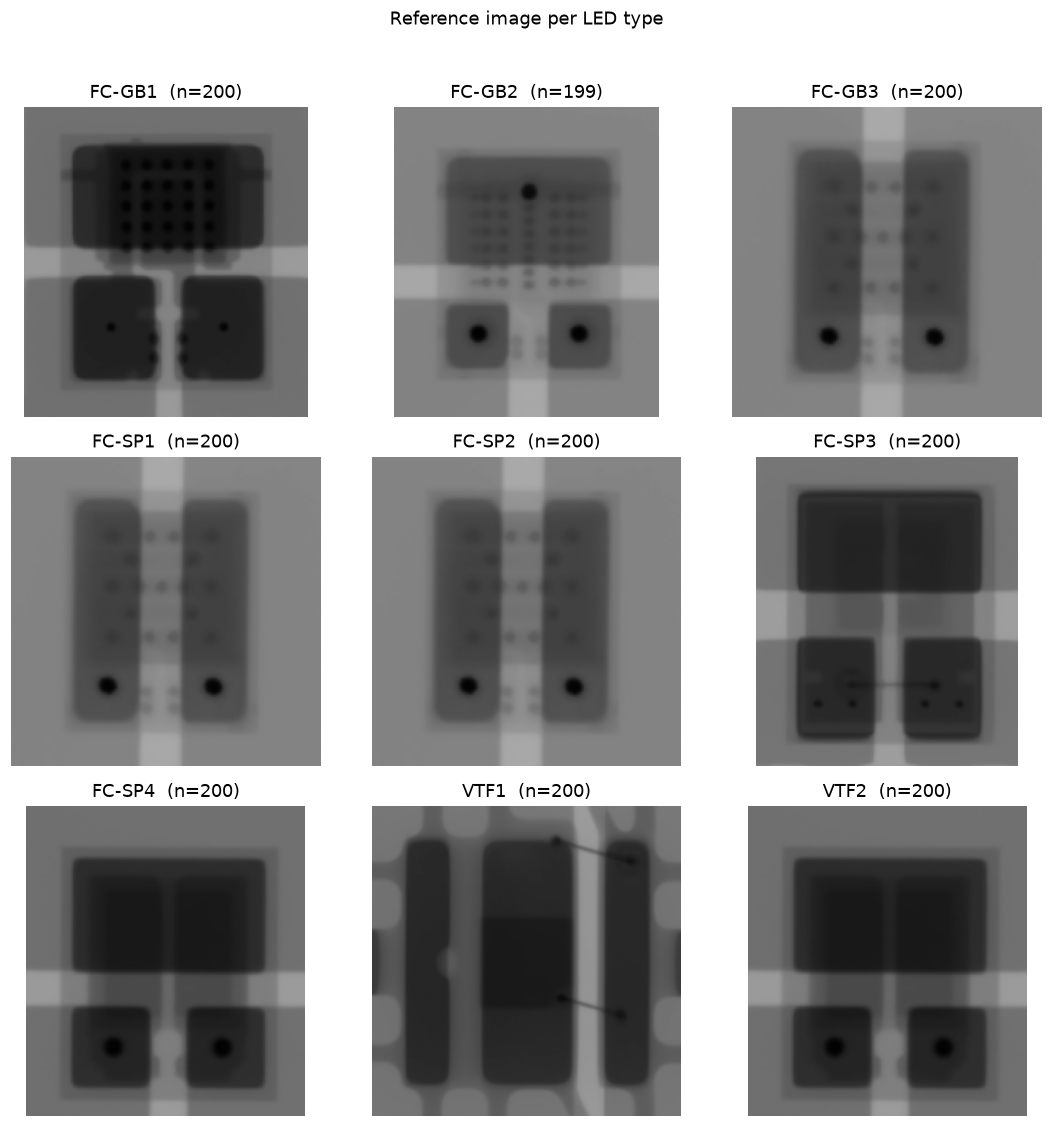


Reference contrast (max - min intensity) per LED type:
   FC-GB1: min=  2, max=155, range=153
   FC-GB2: min=  2, max=169, range=167
   FC-GB3: min=  3, max=170, range=167
   FC-SP1: min=  3, max=170, range=167
   FC-SP2: min=  3, max=170, range=167
   FC-SP3: min= 17, max=159, range=142
   FC-SP4: min=  2, max=155, range=153
     VTF1: min= 12, max=156, range=144
     VTF2: min=  2, max=155, range=153


In [4]:
# Cache references per LED type for reuse in later sections.
# Prints per-type status; catches errors per LED type so one bad type doesn't kill the cell.
REFS = {}

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for ax, t in zip(axes.flat, LED_TYPES):
    try:
        imgs, _ = load_led_type(t)
        if not imgs:
            ax.text(0.5, 0.5, f"{t}\nNO IMAGES", ha="center", va="center")
            ax.axis("off")
            print(f"{t}: NO IMAGES at TSC=0")
            continue
        ref, _ = compute_reference(imgs)
        REFS[t] = ref
        ax.imshow(ref, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{t}  (n={len(imgs)})")
        ax.axis("off")
        print(f"{t}: n={len(imgs)} shape={imgs[0].shape} ref min={ref.min()} max={ref.max()}")
    except Exception as e:
        ax.text(0.5, 0.5, f"{t}\n{type(e).__name__}", ha="center", va="center", color="red")
        ax.axis("off")
        print(f"{t}: ERROR {type(e).__name__}: {e}")

# Hide any unused subplots if LED_TYPES has fewer than 9 entries
for ax in list(axes.flat)[len(LED_TYPES):]:
    ax.axis("off")

plt.suptitle("Reference image per LED type", y=1.02)
plt.tight_layout()
plt.show()

print("\nReference contrast (max - min intensity) per LED type:")
for t, r in REFS.items():
    print(f"  {t:>7s}: min={r.min():3d}, max={r.max():3d}, range={int(r.max()) - int(r.min()):3d}")

### All 9 LED-type references

Each cell below is a separate reference computed from only that type's 200 X-rays. Confirms the pipeline treats every LED type independently.

FC-GB1: n=200 shape=(240, 220) ref min=2 max=155
FC-GB2: n=199 shape=(210, 180) ref min=2 max=169
FC-GB3: n=200 shape=(200, 200) ref min=3 max=170
FC-SP1: n=200 shape=(200, 200) ref min=3 max=170
FC-SP2: n=200 shape=(200, 200) ref min=3 max=170
FC-SP3: n=200 shape=(260, 220) ref min=17 max=159
FC-SP4: n=200 shape=(200, 180) ref min=2 max=155
VTF1: n=200 shape=(300, 300) ref min=12 max=156
VTF2: n=200 shape=(200, 180) ref min=2 max=155


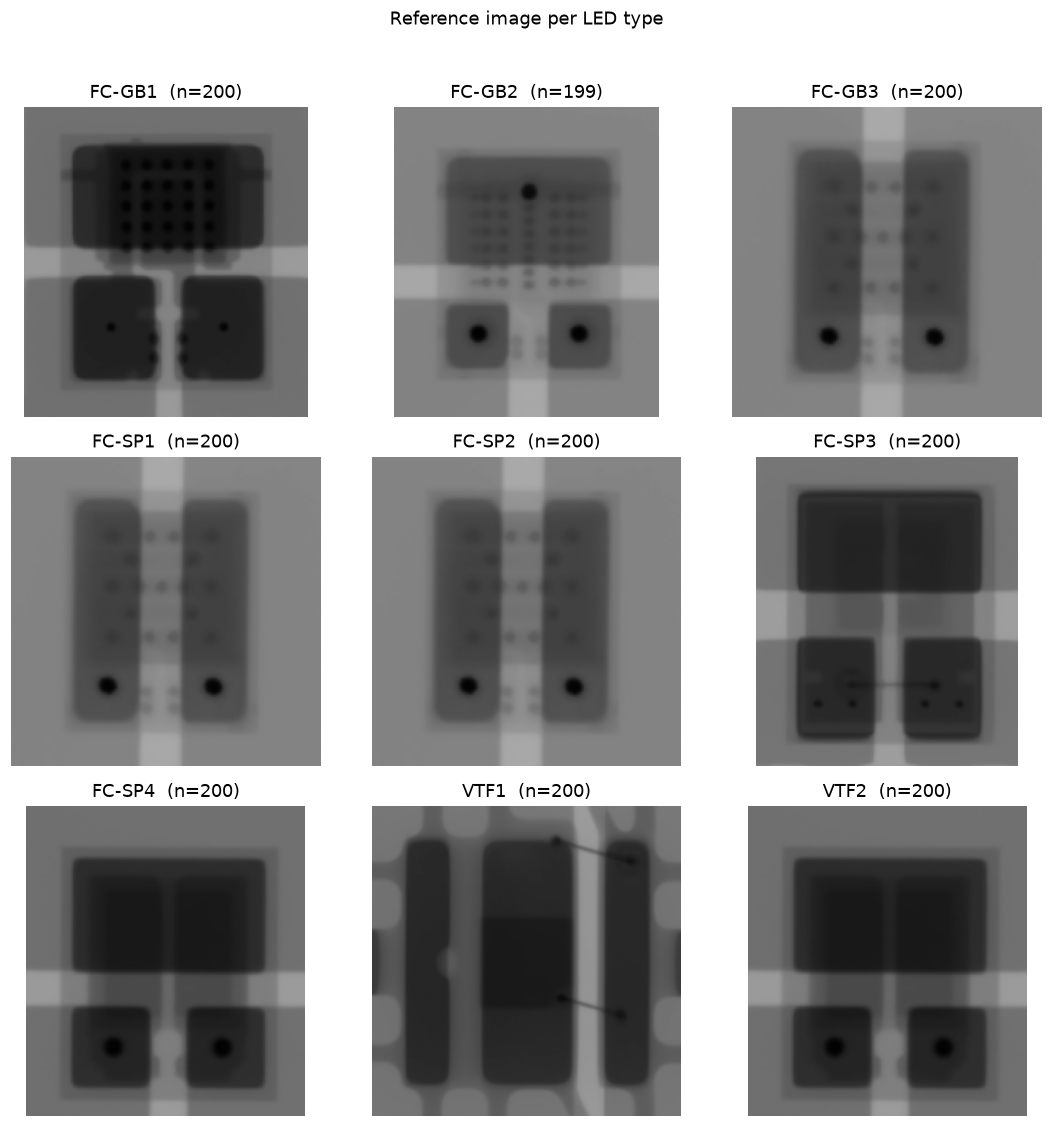

Reference contrast (max - min intensity) per LED type:
   FC-GB1: min=  2, max=155, range=153
   FC-GB2: min=  2, max=169, range=167
   FC-GB3: min=  3, max=170, range=167
   FC-SP1: min=  3, max=170, range=167
   FC-SP2: min=  3, max=170, range=167
   FC-SP3: min= 17, max=159, range=142
   FC-SP4: min=  2, max=155, range=153
     VTF1: min= 12, max=156, range=144
     VTF2: min=  2, max=155, range=153


In [5]:
# Cache references per LED type for reuse in later sections.
# Prints per-type status and catches errors so one bad type does not kill the whole cell.
REFS = {}

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for ax, t in zip(axes.flat, LED_TYPES):
    try:
        imgs, _ = load_led_type(t)
        if not imgs:
            ax.text(0.5, 0.5, f"{t}NO IMAGES", ha="center", va="center")
            ax.axis("off")
            print(f"{t}: NO IMAGES at TSC=0")
            continue
        ref, _ = compute_reference(imgs)
        REFS[t] = ref
        ax.imshow(ref, cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{t}  (n={len(imgs)})")
        ax.axis("off")
        print(f"{t}: n={len(imgs)} shape={imgs[0].shape} ref min={ref.min()} max={ref.max()}")
    except Exception as e:
        ax.text(0.5, 0.5, f"{t}{type(e).__name__}", ha="center", va="center", color="red")
        ax.axis("off")
        print(f"{t}: ERROR {type(e).__name__}: {e}")
# Hide any unused subplots if LED_TYPES has fewer than 9 entries
for ax in list(axes.flat)[len(LED_TYPES):]:
    ax.axis("off")

plt.suptitle("Reference image per LED type", y=1.02)
plt.tight_layout(); plt.show()

print("Reference contrast (max - min intensity) per LED type:")
for t, r in REFS.items():
    print(f"  {t:>7s}: min={r.min():3d}, max={r.max():3d}, range={int(r.max())-int(r.min()):3d}")


Pads are the **darkest** connected components in the reference. X-ray physics: metal (pad + solder) attenuates X-rays, so pad regions appear darker than the surrounding board/air (Part I §III.A: *"voids appear brighter in the X-ray image since more radiation can pass through the specimen due to missing metallic material"* — the inverse applies to metal). Workflow per LED type:

1. **Dark-pixel mask** — Otsu INV by default; for troublesome types (e.g. VTF2, where the die competes with pad darkness) use a per-type percentile or intensity override via `PAD_THRESH_OVERRIDE`.
2. **Iterative erosion** (3×3 kernel, up to `MAX_EROSION_OVERRIDE[led_type]` passes; default 8, 20 for VTF2) — splits touching pads into separate connected components without needing a physically visible gap.
3. **Connected components** → keep the N biggest where N ∈ {2, 3} depending on LED type.
4. **Dilate back + clip** against the original dark-pixel mask — recovers each pad's full extent without bleeding into neighbors.
5. **Assign roles:** 3-pad LEDs → largest = thermal, others = electrical; 2-pad LEDs → both electrical.

This replaces hand-coded pad layouts and adapts to each LED type's image size and geometry automatically. Per Part I §II.A text (and Part II Table I pad-count row): FC-SP1, FC-SP2, FC-GB3 are 2-pad designs; the rest are 3-pad. The thermal pad is the largest for 3-pad types (Part II §II.A: *"for three-pad designs, the thermal pad is typically bigger compared to the electrical pads"*).

FC-SP3 detected pads:
  (34, 28, 190, 116, 'thermal', 13500)
  (33, 151, 102, 239, 'electrical', 5790)
  (122, 151, 190, 239, 'electrical', 5784)


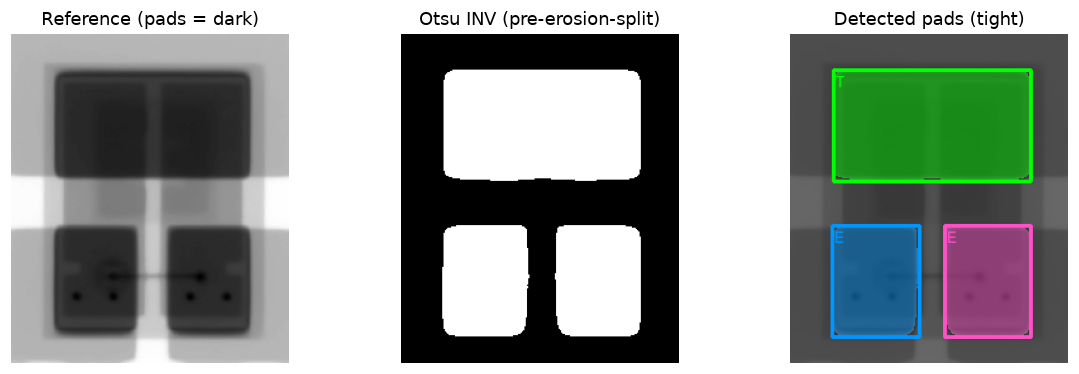

In [6]:
# Pad counts per LED type (Part I §II.A text; Part II Table I)
PAD_COUNT = {
    "FC-SP1": 2, "FC-SP2": 2, "FC-GB3": 2,
    "FC-SP3": 3, "FC-SP4": 3, "FC-GB1": 3, "FC-GB2": 3,
    "VTF1":   3, "VTF2":   3,
}

# Per-LED-type threshold override (controls initial dark-pixel mask).
# Each entry: percentile value = darkest N% of pixels become pad candidates.
#   - Lower value  → stricter (captures only the darkest pixels)
#   - Higher value → looser (captures more mid-tone features)
# Starting values: 30% for most, 20% for VTF2 (die competes with pads).
PAD_THRESH_OVERRIDE = {
    "FC-SP1": {"mode": "percentile", "value": 20},
    # "FC-SP2": {"mode": "percentile", "value": 30},
    "FC-SP3": {"mode": "intensity", "value": 15},
    "FC-SP4": {"mode": "percentile", "value": 40},
    "FC-GB1": {"mode": "percentile", "value": 40},
    "FC-GB2": {"mode": "percentile", "value": 30},
    "FC-GB3": {"mode": "percentile", "value": 30},
    "VTF1":   {"mode": "percentile", "value": 42},
    "VTF2":   {"mode": "percentile", "value": 40},
}

# Per-LED-type erosion budget (how many 3×3 erosion passes before giving up on splitting).
# Higher = more aggressive splitting of fused pads. Default 8 for most; 20 for VTF2.
MAX_EROSION_OVERRIDE = {
    "FC-SP1": 8,
    "FC-SP2": 8,
    "FC-SP3": 8,
    "FC-SP4": 8,
    "FC-GB1": 8,
    "FC-GB2": 8,
    "FC-GB3": 8,
    "VTF1":   8,
    "VTF2":   20,
}

def _initial_pad_mask(reference, led_type):
    """Return the initial dark-pixel mask using Otsu INV, or a per-type percentile override."""
    override = PAD_THRESH_OVERRIDE.get(led_type)
    if override and override["mode"] == "percentile":
        thresh_val = int(np.percentile(reference, override["value"]))
        _, mask = cv2.threshold(reference, thresh_val, 255, cv2.THRESH_BINARY_INV)
        return mask
    _, mask = cv2.threshold(reference, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return mask


def detect_pads(reference, led_type, min_area_frac=0.02, max_erosion=None):
    """Find pad bounding boxes in the reference image.

    X-ray physics: pads are DARKER than the surrounding board (Part I §III.A).

    Algorithm:
      1. Dark-pixel mask (Otsu INV, or percentile threshold for types in PAD_THRESH_OVERRIDE).
      2. Erode iteratively until we have >= n_expected components.
      3. For each kept component, dilate back by the same number of erosions AND
         clip with the original mask so the bbox does not bleed into neighbors.

    Returns (pads_list, per_pad_masks).
    """
    n_expected = PAD_COUNT.get(led_type, 3)
    if max_erosion is None:
        max_erosion = MAX_EROSION_OVERRIDE.get(led_type, 8)
    min_area = int(min_area_frac * reference.size)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

    # 1. Initial dark-pixel mask
    mask0 = _initial_pad_mask(reference, led_type)

    # 2. Iterative erosion until components split
    mask = mask0.copy()
    erosions_used = 0
    regions = []
    for i in range(max_erosion + 1):
        lbl = label(mask > 0)
        regions = [r for r in regionprops(lbl) if r.area >= min_area]
        if len(regions) >= n_expected:
            erosions_used = i
            break
        mask = cv2.erode(mask, kernel)

    # 3. Top-N by area
    regions = sorted(regions, key=lambda r: r.area, reverse=True)[:n_expected]

    # 4. Dilate back + clip with original mask
    pads = []
    per_pad_masks = []
    for i, r in enumerate(regions):
        seed = np.zeros_like(mask)
        for (y, x) in r.coords:
            seed[y, x] = 255
        if erosions_used > 0:
            seed = cv2.dilate(seed, kernel, iterations=erosions_used)
            seed = cv2.bitwise_and(seed, mask0)
        ys, xs = np.nonzero(seed)
        if len(ys) == 0:
            continue
        y0, y1 = int(ys.min()), int(ys.max() + 1)
        x0, x1 = int(xs.min()), int(xs.max() + 1)
        role = "thermal" if (n_expected == 3 and i == 0) else "electrical"
        pads.append((x0, y0, x1, y1, role, int(seed.sum() / 255)))
        per_pad_masks.append(seed)
    return pads, per_pad_masks


# --- Demo ---
pads, pad_masks = detect_pads(reference, "FC-SP3")
print("FC-SP3 detected pads:")
for p in pads:
    print(" ", p)

_, otsu_only = cv2.threshold(reference, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

vis = cv2.cvtColor(reference, cv2.COLOR_GRAY2BGR)
colors = [(0, 255, 0), (255, 150, 0), (200, 80, 255)]
overlay = np.zeros_like(vis)
for m, col in zip(pad_masks, colors):
    overlay[m > 0] = col
vis = cv2.addWeighted(vis, 0.65, overlay, 0.45, 0)
for (x0, y0, x1, y1, role, _a), col in zip(pads, colors):
    cv2.rectangle(vis, (x0, y0), (x1, y1), col, 2)
    cv2.putText(vis, role[0].upper(), (x0 + 2, y0 + 14),
                cv2.FONT_HERSHEY_SIMPLEX, 0.45, col, 1)

fig, ax = plt.subplots(1, 3, figsize=(11, 3.5))

ax[0].imshow(reference, cmap="gray")
ax[0].set_title("Reference (pads = dark)")
ax[0].axis("off")

ax[1].imshow(otsu_only, cmap="gray")
ax[1].set_title("Otsu INV (pre-erosion-split)")
ax[1].axis("off")

ax[2].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
ax[2].set_title("Detected pads (tight)")
ax[2].axis("off")

plt.tight_layout()
plt.show()

**Cross-check across all 9 LED types** — sanity that the auto-detection finds the right pad count and reasonable geometry for each type.

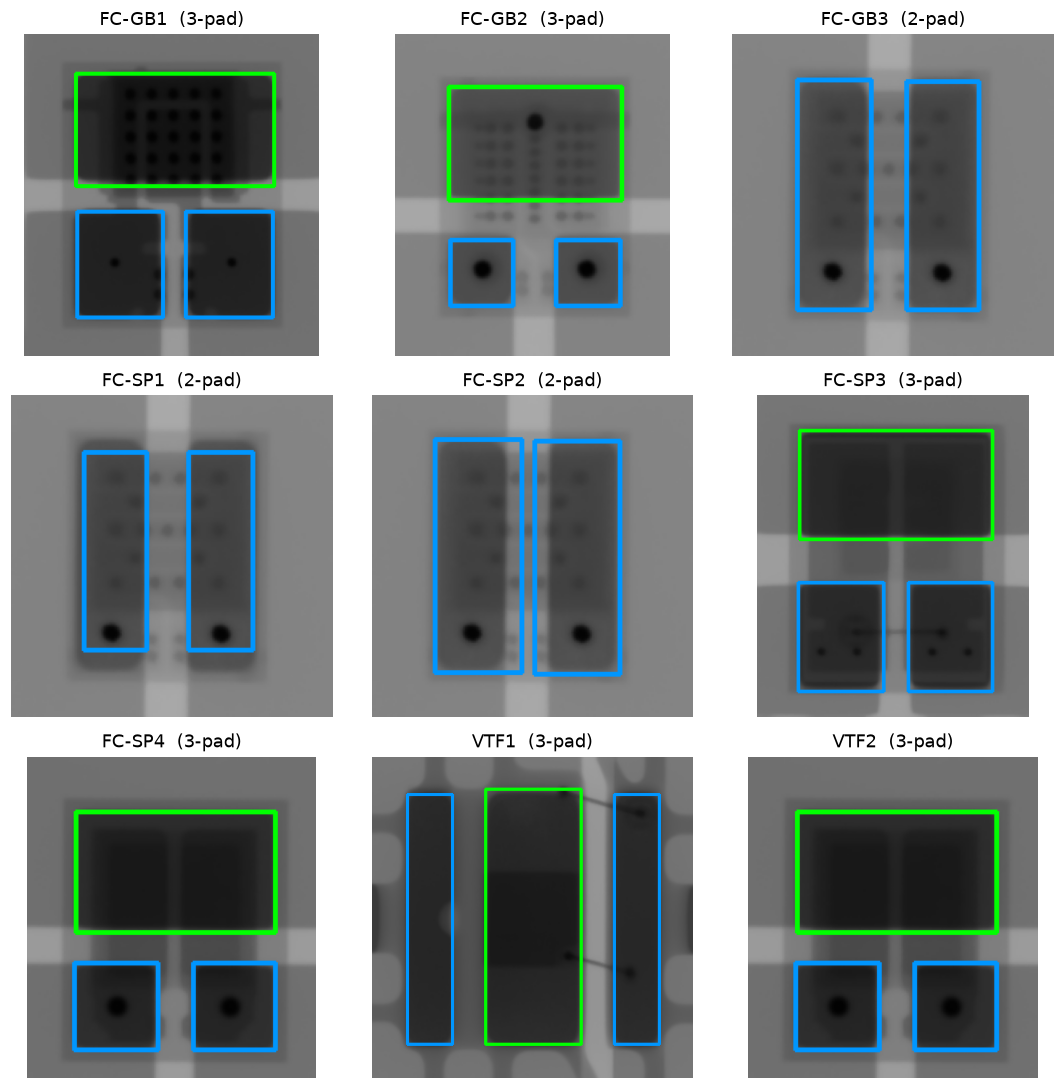

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for ax, t in zip(axes.flat, LED_TYPES):
    imgs, _ = load_led_type(t)
    ref, _ = compute_reference(imgs)
    ps, _ = detect_pads(ref, t)
    vis = cv2.cvtColor(ref, cv2.COLOR_GRAY2BGR)
    for (x0, y0, x1, y1, role, _a) in ps:
        color = (0, 255, 0) if role == "thermal" else (255, 150, 0)
        cv2.rectangle(vis, (x0, y0), (x1, y1), color, 2)
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{t}  ({PAD_COUNT[t]}-pad)")
    ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Void mask extraction

A plain `DUT − reference` does not work on these images: exposure and blur differ from shot to shot, solder thickness adds slow brightness gradients, and die / bumps / wire bonds sit in slightly different places relative to the pads. All of that ends up in the difference image and is larger than the void signal.

So the reference is fitted to each DUT **locally** before subtracting (window of about 8 px):

`DUT ≈ b + a·ref + c·∂ref/∂x + d·∂ref/∂y + e·∇²ref`

- `a, b` absorb local brightness/contrast, `c, d` a local sub-pixel shift, `e` a blur difference.
- Voids are not in the reference, so they remain in the residual. Outlier pixels are removed from the fit and the fit is repeated, so voids do not bias it.
- Residual → hysteresis threshold `T` (per LED type, see `VOID_T`) → drop blobs under 8 px and long thin blobs (pad-outline offsets, edges of shifted structures).

The void ratio is `void pixels / pad pixels`, the same definition as in `Xray Void Ratio.csv`.

    led_type   paste  panel  led_num
895   FC-SP4  SAC105      2        7


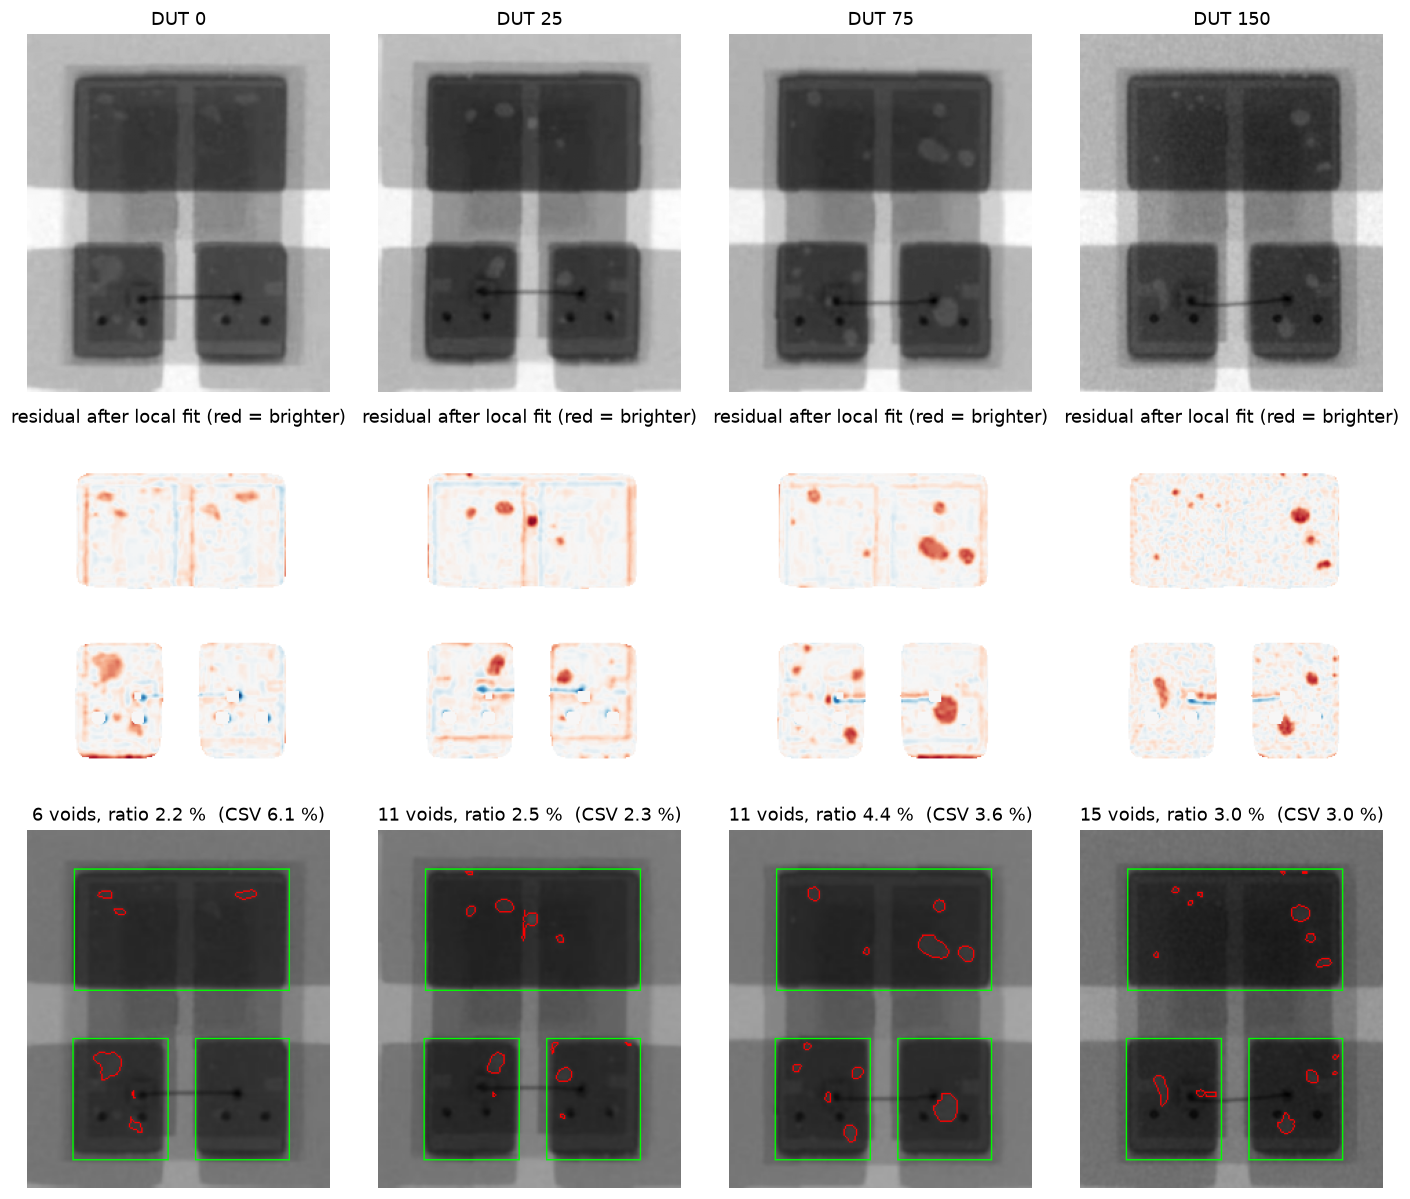

In [8]:
from skimage.filters import apply_hysteresis_threshold

_K3 = np.ones((3, 3), np.uint8)

# Detection threshold per LED type, in grey levels of the reference image.
# Calibrated once against data/raw/CrackVoid Ratios/Xray Void Ratio.csv (value with the smallest mean absolute
# error of the per-LED void ratio). Re-run calibrate_threshold() further below if the pipeline changes.
VOID_T = {"FC-GB1": 11, "FC-GB2": 16, "FC-GB3": 14, "FC-SP1": 11, "FC-SP2": 13,
          "FC-SP3": 12, "FC-SP4": 13, "VTF1": 10, "VTF2": 12}


# ---------- 1. local fit of the DUT to the reference ----------
def _ref_features(ref):
    """Regressors: 1, ref, d(ref)/dx, d(ref)/dy, laplacian(ref)."""
    r = cv2.GaussianBlur(ref.astype(np.float32), (0, 0), 1.0)
    return np.stack([np.ones_like(r), ref.astype(np.float32),
                     cv2.Sobel(r, cv2.CV_32F, 1, 0, ksize=3) / 8, cv2.Sobel(r, cv2.CV_32F, 0, 1, ksize=3) / 8,
                     cv2.Laplacian(r, cv2.CV_32F, ksize=3)], axis=-1)


MIN_POLYFIT_POINTS = 32   # minimum mask pixels required for a reliable polyfit


def _global_gain(img, ref, mask):
    """Robust slope/offset of img against ref = contrast of this shot relative to the reference.

    Returns (a, b) where img ~= a * ref + b inside the mask.
    Falls back to (1.0, 0.0) if the mask contains fewer than MIN_POLYFIT_POINTS pixels.
    """
    import warnings as _warnings
    x, y = ref[mask > 0], img[mask > 0]
    if x.size < MIN_POLYFIT_POINTS:
        _warnings.warn(
            f"_global_gain: only {x.size} mask pixels "
            f"(< MIN_POLYFIT_POINTS={MIN_POLYFIT_POINTS}); "
            "falling back to gain=1.0, offset=0.0.",
            RuntimeWarning, stacklevel=2,
        )
        return 1.0, 0.0
    keep = np.ones_like(x, bool)
    for _ in range(3):
        a, b = np.polyfit(x[keep], y[keep], 1)
        res = y - (a * x + b)
        s = 1.4826 * np.median(np.abs(res[keep] - np.median(res[keep]))) + 1e-6
        keep = np.abs(res) < 2.5 * s
    return a, b


def _local_residual(img, X, fit_mask, a0, sigma_w=8.0, n_iter=3, k_out=2.0, ridge=4.0):
    """Inside a Gaussian window (sigma_w px) around every pixel fit
           img ~ b + a*ref + c*dref/dx + d*dref/dy + e*lap(ref)
       b, a : local brightness / contrast     (exposure differences, solder-thickness gradients)
       c, d : local sub-pixel shift           (die, bumps and wire bonds move a little relative to the pads)
       e    : blur difference
    Voids are not in the reference, so they are what is left over. Outliers are removed from the fit and
    the fit is repeated, so the voids themselves do not pull the local brightness up."""
    H, W, K = X.shape
    ys, xs = np.nonzero(fit_mask)
    w = fit_mask.astype(np.float32)
    lam = np.full(K, ridge, np.float32); lam[0] = 0.0
    beta0 = np.zeros(K, np.float32); beta0[1] = a0                    # shrink towards the global contrast
    for _ in range(n_iter):
        mw = cv2.GaussianBlur(w, (0, 0), sigma_w)[ys, xs] + 1e-6
        A = np.zeros((len(ys), K, K), np.float32)
        for i, j in zip(*np.triu_indices(K)):
            v = cv2.GaussianBlur(w * X[..., i] * X[..., j], (0, 0), sigma_w)[ys, xs] / mw
            A[:, i, j] = v; A[:, j, i] = v
        rhs = np.stack([cv2.GaussianBlur(w * X[..., i] * img, (0, 0), sigma_w)[ys, xs] / mw for i in range(K)], -1)
        A[:, np.arange(K), np.arange(K)] += lam
        rhs += lam * beta0
        beta = np.linalg.solve(A.astype(np.float64), rhs[..., None].astype(np.float64))[..., 0]
        resid = np.zeros((H, W), np.float32)
        resid[ys, xs] = img[ys, xs] - (beta * X[ys, xs]).sum(-1)
        r = resid[ys, xs]
        s = 1.4826 * np.median(np.abs(r - np.median(r))) + 1e-6
        out = cv2.dilate(((resid > k_out * s) & (fit_mask > 0)).astype(np.uint8), _K3)     # bright outliers (voids)
        out |= ((resid < -2 * k_out * s) & (fit_mask > 0)).astype(np.uint8)                # strong dark outliers
        w = ((fit_mask > 0) & (out == 0)).astype(np.float32)
    return resid


# ---------- 2. everything that is computed once per LED type ----------
def build_void_context(led_type, tsc=0):
    imgs, meta_rows = load_led_type(led_type, tsc)
    reg = register_led_type(imgs, led_type=led_type)
    ref = reg["reference"]
    pads_bbox, per_pad = detect_pads(np.clip(ref, 0, 255).astype(np.uint8), led_type)
    pad = np.zeros(ref.shape, np.uint8)
    for m in per_pad:
        pad |= (m > 0).astype(np.uint8)
    # small, very dark features of the package (bump grid, vias, wire-bond balls): never solder -> ignored
    pad_level = np.median(ref[cv2.erode(pad, _K3, iterations=3) > 0])
    blackhat = cv2.morphologyEx(ref, cv2.MORPH_BLACKHAT, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11)))
    dark = cv2.dilate((blackhat > max(8.0, 0.3 * pad_level)).astype(np.uint8), _K3, iterations=2)
    detect_region = cv2.erode(pad, _K3, iterations=2)                 # stay 2 px away from the pad outline
    return dict(led_type=led_type, meta=meta_rows, aligned=reg["aligned"], valid=reg["valid"], ok=reg["ok"],
                reference=ref, pads=pads_bbox, pad_masks=per_pad, pad=pad, dark=dark, X=_ref_features(ref),
                fit_region=cv2.dilate(pad, _K3, iterations=4), detect_region=detect_region,
                edge_dist=ndi.distance_transform_edt(detect_region))


def void_residual(ctx, i):
    """Residual of DUT i (grey levels of the reference; positive = brighter than expected = less metal)."""
    img = ctx["aligned"][i]
    fit = ctx["fit_region"] & ctx["valid"][i] & (1 - ctx["dark"])
    import warnings as _warnings
    a0, _ = _global_gain(img, ctx["reference"], ctx["fit_region"] & ctx["valid"][i])
    resid = _local_residual(img, ctx["X"], fit, a0)
    if a0 <= 0.05:
        _warnings.warn(
            f"void_residual (i={i}): global gain a0={a0:.4f} <= 0.05 "
            "(inverted or degenerate contrast); skipping normalisation, "
            "returning raw residual.",
            RuntimeWarning, stacklevel=2,
        )
        return resid
    return resid / a0


# ---------- 3. residual -> void mask ----------
def extract_void_mask(ctx, i, T=None, hyst=0.6, min_area=8, resid=None):
    """Binary void mask (0/1) of DUT i of the LED type described by ctx.

    T         : threshold in grey levels (default: calibrated VOID_T of this LED type)
    hyst      : a blob must exceed T somewhere and is then grown down to hyst*T (hysteresis)
    min_area  : smallest void in pixels (the reference data contains no void smaller than 8 px)
    Blobs that are long and thin are dropped: along the pad outline they are solder/pad offsets, elsewhere
    they are edges of shifted internal structures - neither is a void.
    """
    if not ctx["ok"][i]:
        return np.zeros(ctx["pad"].shape, np.uint8)
    T = VOID_T[ctx["led_type"]] if T is None else T
    R = void_residual(ctx, i) if resid is None else resid
    region = ctx["detect_region"] & ctx["valid"][i] & (1 - ctx["dark"])
    lbl = label(apply_hysteresis_threshold(np.where(region > 0, R, -99), hyst * T, T), connectivity=2)
    mask = np.zeros(R.shape, np.uint8)
    for r in regionprops(lbl):
        if r.area < min_area:
            continue
        elong = r.axis_major_length / max(r.axis_minor_length, 1.0)
        near_edge = (ctx["edge_dist"][r.coords[:, 0], r.coords[:, 1]] <= 3).mean()
        if (elong >= 3 and near_edge >= 0.6) or (elong >= 4 and r.axis_major_length >= 30):
            continue
        mask[lbl == r.label] = 1
    return mask


def void_stats(ctx, i, mask):
    """Same quantities as the columns of Xray Void Ratio.csv."""
    pad_px = int((ctx["pad"] & ctx["valid"][i]).sum())
    void_px = int(mask.sum())
    return dict(pad_px=pad_px, void_count=int(label(mask).max()), void_px=void_px,
                void_ratio=void_px / pad_px if ctx["ok"][i] and pad_px else np.nan)


def draw_void_outlines(dut_img, void_mask, pads_bbox=None,
                       void_color=(0, 0, 255), pad_color=(0, 255, 0),
                       thickness=1):
    """Return a color image of the DUT with void contours (red) and optional pad boxes (green)."""
    vis = cv2.cvtColor(np.clip(dut_img, 0, 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)
    contours, _ = cv2.findContours((void_mask > 0).astype(np.uint8),
                                   cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(vis, contours, -1, void_color, thickness)
    if pads_bbox is not None:
        for (x0, y0, x1, y1, _r, _a) in pads_bbox:
            cv2.rectangle(vis, (x0, y0), (x1, y1), pad_color, 1)
    return vis, len(contours)


# ---------- reference values (paper's own per-LED result) ----------
GT_CSV = Path("../data/raw/CrackVoid Ratios/Xray Void Ratio.csv")
gt_df = pd.read_csv(GT_CSV, sep=";", na_values=["---"])
gt_df.columns = ["led_type", "paste", "panel", "led_num", "csv_pad_px", "csv_void_count", "csv_void_px", "csv_void_ratio"]
_KEY = ["led_type", "paste", "panel", "led_num"]
_dup_mask = gt_df.duplicated(_KEY, keep=False)
if _dup_mask.any():
    import logging as _logging
    _logging.warning(
        "CSV dedup: dropping %d duplicate-key rows (keeping first occurrence). "
        "Affected keys:\n%s",
        _dup_mask.sum(),
        gt_df[_dup_mask][_KEY].drop_duplicates().to_string(),
    )
gt_df = gt_df.drop_duplicates(_KEY, keep='first')          # FC-SP4 / SAC105 / panel 2 lists LED 7 twice -> keep first, log dropped


# ---------- demo on FC-SP3: raw DUT | residual | outlined voids ----------
ctx = build_void_context("FC-SP3")
aligned = [np.clip(a, 0, 255).astype(np.uint8) for a in ctx["aligned"]]
reference = np.clip(ctx["reference"], 0, 255).astype(np.uint8)
pads, pad_masks = ctx["pads"], ctx["pad_masks"]
csv_sp3 = pd.DataFrame(ctx["meta"]).merge(gt_df, on=_KEY, how="left")["csv_void_ratio"].values

fig, ax = plt.subplots(3, 4, figsize=(13, 11))
for c, idx in enumerate([0, 25, 75, 150]):
    R = void_residual(ctx, idx)
    mask = extract_void_mask(ctx, idx, resid=R)
    st = void_stats(ctx, idx, mask)
    vis, n_voids = draw_void_outlines(aligned[idx], mask, pads_bbox=pads)
    ax[0, c].imshow(aligned[idx], cmap="gray"); ax[0, c].set_title(f"DUT {idx}")
    ax[1, c].imshow(np.where(ctx["detect_region"] > 0, R, np.nan), cmap="RdBu_r", vmin=-25, vmax=25)
    ax[1, c].set_title("residual after local fit (red = brighter)")
    ax[2, c].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    ax[2, c].set_title(f"{n_voids} voids, ratio {100*st['void_ratio']:.1f} %  (CSV {100*csv_sp3[idx]:.1f} %)")
    for r in range(3):
        ax[r, c].axis("off")
plt.tight_layout(); plt.show()

In [9]:
def calibrate_threshold(ctx, Ts=range(6, 21)):
    """Sweep the threshold T for one LED type and compare the per-LED void ratio with the CSV.
    Returns a table (T, mean absolute error in %-points, Pearson r, mean ratio ours / CSV)."""
    csv = pd.DataFrame(ctx["meta"]).merge(gt_df, on=_KEY, how="left")["csv_void_ratio"].values
    use = ctx["ok"] & ~np.isnan(csv)
    resid = {i: void_residual(ctx, i) for i in np.where(use)[0]}          # the slow part, done once
    rows = []
    for T in Ts:
        ours = np.array([void_stats(ctx, i, extract_void_mask(ctx, i, T=T, resid=resid[i]))["void_ratio"] for i in resid])
        ref = csv[list(resid)]
        rows.append(dict(T=T, mae=100 * np.abs(ours - ref).mean(), r=np.corrcoef(ours, ref)[0, 1],
                         mean_ours=100 * ours.mean(), mean_csv=100 * ref.mean()))
    return pd.DataFrame(rows)


# FC-SP3 as an example (about 30 s). The T with the smallest error is what VOID_T holds for this type.
cal = calibrate_threshold(ctx)
print(f"best T for FC-SP3: {int(cal.loc[cal.mae.idxmin(), 'T'])}   (VOID_T = {VOID_T['FC-SP3']})")
cal.round(2)

best T for FC-SP3: 12   (VOID_T = 12)


,T,mae,r,mean_ours,mean_csv
0,6,2.73,0.83,5.08,2.37
1,7,1.92,0.87,4.28,2.37
2,8,1.33,0.90,3.67,2.37
3,9,0.88,0.91,3.21,2.37
4,10,0.60,0.93,2.87,2.37
5,11,0.43,0.93,2.58,2.37
6,12,0.38,0.92,2.33,2.37
7,13,0.42,0.90,2.11,2.37
8,14,0.53,0.85,1.89,2.37
9,15,0.74,0.73,1.64,2.37


> **Calibration caveat:** `VOID_T` is calibrated on the **same CSV** that is used
> for the threshold sweep — the Pearson *r* and MAE values reported by
> `calibrate_threshold` are a **training fit**, not held-out performance.
> A panel-split cross-validation (e.g. leave-one-panel-out) is needed
> before claiming generalisation to unseen panels or LED types.
> **Do not report these numbers as test-set metrics.**

### Diagnostic — why the plain difference image is not enough

The cell below shows the plain `DUT − reference` for one DUT and a threshold sweep on it. Compare it with the residual row in the figure above: pad edges and internal structures light up in the plain difference, which is what the local fit removes.

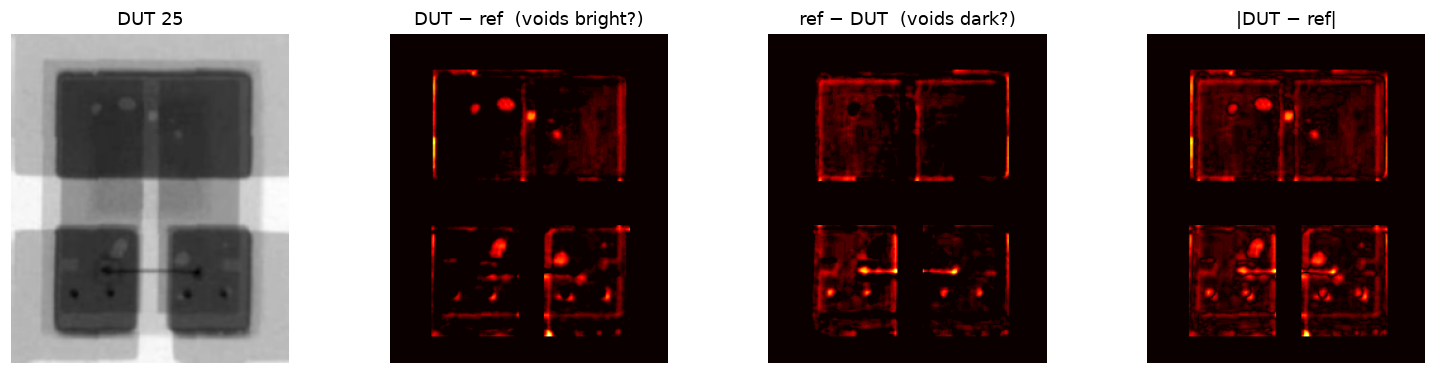

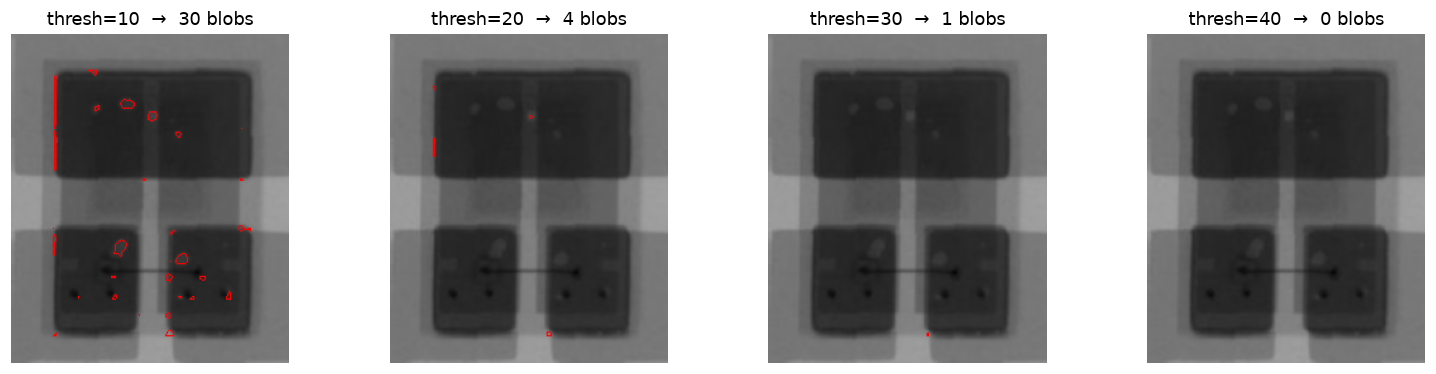

DUT − ref inside pads: mean=1.60, std=3.14, p90=5.0, p99=15.0, max=36
If p99 is only a few counts above the mean, the threshold needs to be much lower (try 5–10).
If the mean is already high (>30), the reference is bleeding into the DUTs — likely alignment issue.


In [10]:
DUT_INDEX = 25   # change this to a DUT you can see voids on
dut = aligned[DUT_INDEX]

diff_pos = cv2.subtract(dut, reference)   # voids-are-brighter hypothesis
diff_neg = cv2.subtract(reference, dut)   # voids-are-darker  hypothesis
diff_abs = cv2.absdiff(dut, reference)

# Pad-restrict helper for cleaner viz
pad_mask = np.zeros_like(dut)
for (x0, y0, x1, y1, _r, _a) in pads:
    pad_mask[y0:y1, x0:x1] = 1

fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))
ax[0].imshow(dut, cmap="gray");                 ax[0].set_title(f"DUT {DUT_INDEX}")
ax[1].imshow(diff_pos * pad_mask, cmap="hot");  ax[1].set_title("DUT − ref  (voids bright?)")
ax[2].imshow(diff_neg * pad_mask, cmap="hot");  ax[2].set_title("ref − DUT  (voids dark?)")
ax[3].imshow(diff_abs * pad_mask, cmap="hot");  ax[3].set_title("|DUT − ref|")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# ----- Threshold sweep on the brighter-hypothesis (switch to diff_neg if that one lit up instead) -----
diff = diff_pos
thresholds = [10, 20, 30, 40]
fig, ax = plt.subplots(1, len(thresholds), figsize=(14, 3.5))
for i, th in enumerate(thresholds):
    _, m = cv2.threshold(diff, th, 255, cv2.THRESH_BINARY)
    m = cv2.bitwise_and(m, (pad_mask * 255).astype(np.uint8))
    vis = cv2.cvtColor(dut, cv2.COLOR_GRAY2BGR)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(vis, cnts, -1, (0, 0, 255), 1)
    ax[i].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    ax[i].set_title(f"thresh={th}  →  {len(cnts)} blobs")
    ax[i].axis("off")
plt.tight_layout(); plt.show()

# ----- Signal histogram inside pad regions only -----
vals = diff[pad_mask > 0]
print(f"DUT − ref inside pads: mean={vals.mean():.2f}, std={vals.std():.2f}, "
      f"p90={np.percentile(vals, 90):.1f}, p99={np.percentile(vals, 99):.1f}, max={vals.max()}")
print("If p99 is only a few counts above the mean, the threshold needs to be much lower (try 5–10).")
print("If the mean is already high (>30), the reference is bleeding into the DUTs — likely alignment issue.")

## 5. Per-pad feature extraction

Features are computed in **pad-normalized coordinates**: pad center = (0, 0), corners = (±1, ±1). This makes them comparable across LED types with different pad sizes.

In [11]:
# --- Named constants for pad feature extraction ---
PAD_IN_FRAME_THRESHOLD = 0.9   # pads with less coverage than this are gated (all features -> NaN)
INNER_RADIUS_FRAC = 0.5        # inner concentric region boundary: 0.5 * r_eq
ASYM_EPS = 1e-9                # denominator guard for electrical asymmetry


def pad_features(void_mask, pad_bbox, per_pad_mask=None, valid_mask=None):
    """Compute spatial void features for one pad, in normalized pad coordinates.

    Parameters
    ----------
    void_mask : ndarray (H, W) uint8
        Binary void mask (1 = void pixel) for the full image.
    pad_bbox : tuple
        (x0, y0, x1, y1, role, area_px) — bounding box and role of this pad.
    per_pad_mask : ndarray (H, W) uint8 or None
        Full-image binary mask of this pad's exact shape.  If None, the bbox
        rectangle is used as a fallback.
    valid_mask : ndarray (H, W) uint8 or None
        Full-image mask: 1 where the registered image has valid pixel data.
        Used to compute pad_in_frame_frac and gate unreliable pads.

    Returns
    -------
    dict
        Per-pad feature dictionary.  When pad_in_frame_frac < PAD_IN_FRAME_THRESHOLD
        all void-dependent features are set to NaN and a warning is printed.
    """
    x0, y0, x1, y1, role, _area_px = pad_bbox
    pad_crop = void_mask[y0:y1, x0:x1]
    pad_h, pad_w = pad_crop.shape
    pad_area = pad_h * pad_w

    # ------------------------------------------------------------------
    # Fix 4 — pad_in_frame_frac: fraction of this pad inside the valid
    # registered-image region.  Gate the pad if coverage is too low.
    # ------------------------------------------------------------------
    if per_pad_mask is not None and valid_mask is not None:
        pad_pixels = float((per_pad_mask > 0).sum())
        in_frame   = float(((per_pad_mask > 0) & (valid_mask > 0)).sum())
        pad_in_frame_frac = (in_frame / pad_pixels) if pad_pixels > 0 else 0.0
    elif valid_mask is not None:
        # fallback: use bbox
        bbox_pixels = float(pad_area)
        in_frame = float(valid_mask[y0:y1, x0:x1].sum())
        pad_in_frame_frac = (in_frame / bbox_pixels) if bbox_pixels > 0 else 0.0
    else:
        pad_in_frame_frac = 1.0   # no valid mask supplied: assume fully in frame

    _NAN_FEATS = {
        "void_area_frac": np.nan,
        "centroid_x": np.nan, "centroid_y": np.nan,
        "q_NW": np.nan, "q_NE": np.nan, "q_SW": np.nan, "q_SE": np.nan,
        "cluster_count": np.nan, "mean_circularity": np.nan,
        "largest_void_frac": np.nan, "edge_proximity_min": np.nan,
        "center_frac": np.nan, "edge_frac": np.nan,
        "largest_void_centroid_r": np.nan,
        "largest_void_edge_dist": np.nan,
        "largest_void_circularity": np.nan,
        "radial_var": np.nan, "radial_skew": np.nan,
        "pad_in_frame_frac": pad_in_frame_frac,
    }

    if pad_in_frame_frac < PAD_IN_FRAME_THRESHOLD:
        import warnings as _w
        _w.warn(
            f"pad_features: pad ({role}, bbox=({x0},{y0})-({x1},{y1})) "
            f"pad_in_frame_frac={pad_in_frame_frac:.3f} < {PAD_IN_FRAME_THRESHOLD} "
            "— all features set to NaN.",
            RuntimeWarning, stacklevel=2,
        )
        return _NAN_FEATS

    feats = {
        "void_area_frac": float(pad_crop.sum()) / pad_area,
        "pad_in_frame_frac": pad_in_frame_frac,
    }

    # --- zero-void fast path ---
    if pad_crop.sum() == 0:
        feats.update({
            "centroid_x": 0.0, "centroid_y": 0.0,
            "q_NW": 0.0, "q_NE": 0.0, "q_SW": 0.0, "q_SE": 0.0,
            "cluster_count": 0, "mean_circularity": np.nan,
            "largest_void_frac": 0.0, "edge_proximity_min": np.nan,
            # Fix 1
            "center_frac": np.nan, "edge_frac": np.nan,
            # Fix 2
            "largest_void_centroid_r": np.nan,
            "largest_void_edge_dist": np.nan,
            "largest_void_circularity": np.nan,
            # Fix 3
            "radial_var": np.nan, "radial_skew": np.nan,
        })
        return feats

    # --- Pad mask & geometry ---
    if per_pad_mask is not None:
        pad_region_mask = (per_pad_mask[y0:y1, x0:x1] > 0).astype(np.uint8)
    else:
        pad_region_mask = np.ones((pad_h, pad_w), dtype=np.uint8)

    _pad_lbl = label(pad_region_mask, connectivity=2)
    _pad_props = regionprops(_pad_lbl)
    if _pad_props:
        pc_y, pc_x = _pad_props[0].centroid      # (row, col) in bbox-local coords
        theta = _pad_props[0].orientation         # radians, CCW from col-axis
    else:
        pc_y, pc_x = pad_h / 2.0, pad_w / 2.0
        theta = 0.0

    # Denominator = per-pad-mask pixel count (or bbox area if mask unavailable).
    pad_area_denom = float(pad_region_mask.sum()) if pad_region_mask.sum() > 0 else float(pad_area)

    # Equivalent radius of this pad (dimensionless normaliser).
    equiv_radius = np.sqrt(pad_area_denom / np.pi)
    r_inner = INNER_RADIUS_FRAC * equiv_radius   # Fix 1 boundary

    # Void pixel coords in bbox-local frame, centred on pad centroid.
    ys_v, xs_v = np.nonzero(pad_crop)
    dy = ys_v - pc_y
    dx = xs_v - pc_x

    # Radial distances of all void pixels from pad centroid (unnormalised, px).
    radii_px = np.hypot(dx, dy)
    radii_norm = radii_px / max(equiv_radius, 1.0)   # dimensionless

    # Rotate void coords into pad principal-axis frame.
    cos_t, sin_t = np.cos(theta), np.sin(theta)
    dx_r =  dx * cos_t + dy * sin_t
    dy_r = -dx * sin_t + dy * cos_t

    # Void centroid in normalised pad coordinates.
    half_w = pad_w / 2.0 if pad_w > 0 else 1.0
    half_h = pad_h / 2.0 if pad_h > 0 else 1.0
    feats["centroid_x"] = float(dx_r.mean()) / half_w
    feats["centroid_y"] = float(dy_r.mean()) / half_h

    # Quadrant counts in principal-axis frame.
    nw = int(((dx_r < 0) & (dy_r < 0)).sum())
    ne = int(((dx_r >= 0) & (dy_r < 0)).sum())
    sw = int(((dx_r < 0) & (dy_r >= 0)).sum())
    se = int(((dx_r >= 0) & (dy_r >= 0)).sum())
    tot = nw + ne + sw + se
    feats.update({"q_NW": nw / tot, "q_NE": ne / tot,
                  "q_SW": sw / tot, "q_SE": se / tot})

    # --- Fix 1: center_frac / edge_frac ---
    # void mass split at INNER_RADIUS_FRAC * r_eq from pad centroid.
    n_total_void = float(ys_v.size)
    n_inner = float((radii_px < r_inner).sum())
    feats["center_frac"] = n_inner / n_total_void
    feats["edge_frac"]   = 1.0 - feats["center_frac"]
    # Verification property: center_frac + edge_frac == 1.0 when voids exist.

    # --- Fix 3: radial second moments ---
    feats["radial_var"]  = float(np.var(radii_norm))
    if radii_norm.size >= 2:
        feats["radial_skew"] = float(_scipy_skew(radii_norm, nan_policy="omit"))
    else:
        feats["radial_skew"] = np.nan

    # --- Void cluster regionprops ---
    lbl = label(pad_crop, connectivity=2)
    regions = regionprops(lbl)
    feats["cluster_count"] = len(regions)
    areas  = np.array([r.area for r in regions], dtype=float)
    perims = np.array([r.perimeter if r.perimeter > 0 else 1.0 for r in regions])
    circs  = 4 * np.pi * areas / (perims ** 2)
    feats["mean_circularity"]  = float(np.average(circs, weights=areas))
    feats["largest_void_frac"] = float(areas.max()) / pad_area_denom

    # Largest void region (by area).
    _lv_idx = int(np.argmax(areas))
    _lv_region = regions[_lv_idx]

    # --- Fix 2: largest-void geometry ---
    # (a) centroid_r: radial distance of largest-void centroid from pad centroid,
    #     normalised by equiv_radius.
    lv_cy_local, lv_cx_local = _lv_region.centroid   # (row, col) in bbox-local
    lv_dy = lv_cy_local - pc_y
    lv_dx = lv_cx_local - pc_x
    lv_r_px = np.hypot(lv_dx, lv_dy)
    feats["largest_void_centroid_r"] = float(lv_r_px) / max(equiv_radius, 1.0)

    # (b) edge_dist: min EDT distance of largest-void pixels from pad boundary,
    #     normalised by equiv_radius.  Uses per_pad_mask EDT when available.
    if per_pad_mask is not None:
        pad_edt = ndi.distance_transform_edt(per_pad_mask > 0)
        # Largest void pixels in full-image coordinates.
        lv_rows = _lv_region.coords[:, 0] + y0
        lv_cols = _lv_region.coords[:, 1] + x0
        # Clip to avoid out-of-bounds if bbox slightly outside image.
        lv_rows = np.clip(lv_rows, 0, pad_edt.shape[0] - 1)
        lv_cols = np.clip(lv_cols, 0, pad_edt.shape[1] - 1)
        feats["largest_void_edge_dist"] = (
            float(pad_edt[lv_rows, lv_cols].min()) / max(equiv_radius, 1.0)
        )
    else:
        # Fallback: bbox-interior EDT at the largest-void pixels.
        interior = np.ones_like(pad_crop, dtype=np.uint8)
        interior[0, :] = 0; interior[-1, :] = 0
        interior[:, 0] = 0; interior[:, -1] = 0
        interior_edt = ndi.distance_transform_edt(interior)
        lv_ys = _lv_region.coords[:, 0]
        lv_xs = _lv_region.coords[:, 1]
        norm = min(pad_h, pad_w) / 2.0
        feats["largest_void_edge_dist"] = float(interior_edt[lv_ys, lv_xs].min()) / max(norm, 1.0)

    # (c) circularity of the single largest void.
    # Prefer perimeter_crofton (more stable for digitized blobs); fall back to .perimeter.
    _lv_perim = getattr(_lv_region, "perimeter_crofton", None)
    if _lv_perim is None or _lv_perim == 0:
        _lv_perim = _lv_region.perimeter if _lv_region.perimeter > 0 else 1.0
    feats["largest_void_circularity"] = float(4 * np.pi * _lv_region.area / (_lv_perim ** 2))

    # --- edge_proximity_min (original; kept for backwards compat) ---
    # pad_edt and equiv_radius were both computed in the Fix 2 / geometry blocks above.
    if per_pad_mask is not None:
        ys_full, xs_full = np.nonzero(
            (void_mask > 0) & (per_pad_mask > 0)
        )
        if ys_full.size > 0:
            feats["edge_proximity_min"] = (
                float(pad_edt[ys_full, xs_full].min()) / max(equiv_radius, 1.0)
            )
        else:
            feats["edge_proximity_min"] = np.nan
    else:
        interior = np.ones_like(pad_crop, dtype=np.uint8)
        interior[0, :]  = 0; interior[-1, :] = 0
        interior[:, 0]  = 0; interior[:, -1] = 0
        dist = ndi.distance_transform_edt(interior)
        normalizer = min(pad_h, pad_w) / 2
        feats["edge_proximity_min"] = float(dist[pad_crop > 0].min()) / normalizer
    return feats


demo_mask = extract_void_mask(ctx, 0)
for bbox, _pmask in zip(pads, pad_masks):
    f = pad_features(demo_mask, bbox, per_pad_mask=_pmask)
    print(f"{bbox[4]:>10s} pad ({bbox[0]},{bbox[1]})-({bbox[2]},{bbox[3]}): "
          f"void_frac={f['void_area_frac']:.4f}, "
          f"centroid=({f['centroid_x']:+.2f}, {f['centroid_y']:+.2f}), "
          f"clusters={f['cluster_count']}")

   thermal pad (34,28)-(190,116): void_frac=0.0127, centroid=(-0.28, +0.08), clusters=3
electrical pad (33,151)-(102,239): void_frac=0.0608, centroid=(-0.09, -0.37), clusters=3
electrical pad (122,151)-(190,239): void_frac=0.0000, centroid=(+0.00, +0.00), clusters=0


## 6. Per-LED feature vector (aggregate pads by role)

Thermal-pad features are kept separately; electrical-pad features are averaged across all electrical pads of that LED. 2-pad LEDs get `thermal_* = NaN` and `has_thermal_pad = 0`.

In [12]:
# All features returned by pad_features that should be aggregated per LED.
# pad_in_frame_frac is listed here so it is surfaced as thermal_pad_in_frame_frac
# and electrical_mean_pad_in_frame_frac (and electrical_min/max/asym variants).
_FEATURE_KEYS = [
    "void_area_frac", "centroid_x", "centroid_y",
    "q_NW", "q_NE", "q_SW", "q_SE",
    "cluster_count", "mean_circularity",
    "largest_void_frac", "edge_proximity_min",
    # Fix 1 — concentric void mass split
    "center_frac", "edge_frac",
    # Fix 2 — largest-void geometry
    "largest_void_centroid_r", "largest_void_edge_dist", "largest_void_circularity",
    # Fix 3 — radial second moments
    "radial_var", "radial_skew",
    # Fix 4 — in-frame fraction
    "pad_in_frame_frac",
]


def led_feature_vector(void_mask, pads_bbox, meta_row, pad_masks=None, valid_mask=None):
    """Build the per-LED feature row.

    Parameters
    ----------
    void_mask : ndarray
        Binary void mask for this DUT image.
    pads_bbox : list of tuples
        Output of detect_pads: [(x0,y0,x1,y1,role,area_px), ...].
    meta_row : dict
        Row from the metadata table (unit_id, led_type, paste, panel, led_num).
    pad_masks : list of ndarray or None
        Per-pad full-image binary masks; aligned with pads_bbox.
    valid_mask : ndarray or None
        Full-image mask: 1 where registered-image pixels are valid (Fix 4 / Fix 6).
    """
    thermal_f, electrical_f = None, []
    for _idx_pad, bbox in enumerate(pads_bbox):
        role = bbox[4]
        _pmask = pad_masks[_idx_pad] if (pad_masks is not None and _idx_pad < len(pad_masks)) else None
        f = pad_features(void_mask, bbox, per_pad_mask=_pmask, valid_mask=valid_mask)
        if role == "thermal":
            thermal_f = f
        else:
            electrical_f.append(f)

    row = {
        "unit_id":   meta_row["unit_id"],
        "led_type":  meta_row["led_type"],
        "paste":     meta_row["paste"],
        "panel":     meta_row["panel"],
        "led_num":   meta_row["led_num"],
        "has_thermal_pad": int(thermal_f is not None),
    }

    # Thermal pad: direct copy.
    for k in _FEATURE_KEYS:
        row[f"thermal_{k}"] = thermal_f[k] if thermal_f else np.nan

    # Electrical pads: mean (kept), plus min / max / asymmetry (Fix 5).
    for k in _FEATURE_KEYS:
        raw_vals = [p[k] for p in electrical_f]
        # _is_nan: safe NaN check that works for int, float, and np.nan.
        def _is_nan(v):
            try:
                return np.isnan(v)
            except (TypeError, ValueError):
                return False
        # Exclude NaN from mean (match original nan-drop behaviour).
        finite_vals = [v for v in raw_vals if not _is_nan(v)]
        row[f"electrical_mean_{k}"] = float(np.mean(finite_vals)) if finite_vals else np.nan

        if len(electrical_f) >= 2:
            # Fix 5 — per-electrical-pad min / max / asymmetry.
            has_finite = any(not _is_nan(v) for v in raw_vals)
            e_min = float(np.nanmin([float(v) for v in raw_vals])) if has_finite else np.nan
            e_max = float(np.nanmax([float(v) for v in raw_vals])) if has_finite else np.nan
            if (not has_finite) or np.isnan(e_min) or np.isnan(e_max):
                e_asym = np.nan
            else:
                e_asym = (e_max - e_min) / (e_max + e_min + ASYM_EPS)
            row[f"electrical_min_{k}"]  = e_min
            row[f"electrical_max_{k}"]  = e_max
            row[f"electrical_asym_{k}"] = e_asym

    return row


row = led_feature_vector(demo_mask, pads, meta[0], pad_masks=pad_masks)
pd.Series(row).to_frame("value")

,value
unit_id,FC-SP3_SAC105_P1_L01
led_type,FC-SP3
paste,SAC105
panel,1
led_num,1
...,...
electrical_asym_radial_skew,-0.0
electrical_mean_pad_in_frame_frac,1.0
electrical_min_pad_in_frame_frac,1.0
electrical_max_pad_in_frame_frac,1.0


## 7. Batch pipeline — all 9 LED types

For each LED type: load → compute reference → detect pads once → extract features for every DUT. Produces the feature DataFrame ready to join with the `TSC_fail` target from `rth_start_end.csv`.

In [13]:
VOID_SAMPLES = {}      # a few DUTs per LED type, kept for the outline gallery below


def process_led_type(led_type, verbose=False):
    c = build_void_context(led_type)
    rows, masks = [], []
    for i, mrow in enumerate(c["meta"]):
        mask = extract_void_mask(c, i)
        row = led_feature_vector(mask, c["pads"], mrow, pad_masks=c["pad_masks"],
                                 valid_mask=c["valid"][i])
        row.update(void_stats(c, i, mask))
        row["image_missing"] = int(not c["ok"][i])
        if not c["ok"][i]:                                   # placeholder picture: no features
            for k in row:
                if k.startswith(("thermal_", "electrical_mean_",
                                  "electrical_min_", "electrical_max_",
                                  "electrical_asym_")):
                    row[k] = np.nan
        rows.append(row); masks.append(mask)
    ratio = np.array([r["void_ratio"] for r in rows])
    order = np.argsort(np.nan_to_num(ratio, nan=-1))
    order = order[np.isfinite(ratio[order])]
    pick = [int(order[int(q * (len(order) - 1))]) for q in (0.1, 0.5, 0.9, 1.0)]     # low / median / high / highest
    VOID_SAMPLES[led_type] = [dict(unit_id=rows[i]["unit_id"], img=np.clip(c["aligned"][i], 0, 255).astype(np.uint8),
                                   mask=masks[i], void_ratio=ratio[i]) for i in pick]
    if verbose:
        print(f"  {led_type}: {len(rows)} imgs, {len(c['pads'])} pads, {int((~c['ok']).sum())} placeholder(s), "
              f"mean void ratio {100*np.nanmean(ratio):.2f} %")
    return rows


all_rows = []
for t in LED_TYPES:
    all_rows.extend(process_led_type(t, verbose=True))

features_df = pd.DataFrame(all_rows).set_index("unit_id")
print(f"\nFeature matrix: {features_df.shape}")
features_df.head()

  FC-GB1: 200 imgs, 3 pads, 0 placeholder(s), mean void ratio 2.37 %
  FC-GB2: 199 imgs, 3 pads, 0 placeholder(s), mean void ratio 1.31 %


C:\Users\JPagtalu\AppData\Local\Temp\ipykernel_74844\2360204831.py:40: RuntimeWarning: pad_features: pad (electrical, bbox=(40,28)-(86,171)) pad_in_frame_frac=0.350 < 0.9 — all features set to NaN.
  f = pad_features(void_mask, bbox, per_pad_mask=_pmask, valid_mask=valid_mask)


  FC-GB3: 200 imgs, 2 pads, 2 placeholder(s), mean void ratio 4.96 %
  FC-SP1: 200 imgs, 2 pads, 0 placeholder(s), mean void ratio 0.45 %
  FC-SP2: 200 imgs, 2 pads, 2 placeholder(s), mean void ratio 2.25 %
  FC-SP3: 200 imgs, 3 pads, 0 placeholder(s), mean void ratio 2.33 %
  FC-SP4: 200 imgs, 3 pads, 0 placeholder(s), mean void ratio 3.20 %


C:\Users\JPagtalu\AppData\Local\Temp\ipykernel_74844\2360204831.py:40: RuntimeWarning: pad_features: pad (electrical, bbox=(226,35)-(268,268)) pad_in_frame_frac=0.900 < 0.9 — all features set to NaN.
  f = pad_features(void_mask, bbox, per_pad_mask=_pmask, valid_mask=valid_mask)


  VTF1: 200 imgs, 3 pads, 2 placeholder(s), mean void ratio 2.58 %
  VTF2: 200 imgs, 3 pads, 0 placeholder(s), mean void ratio 3.39 %

Feature matrix: (1799, 105)


,led_type,paste,panel,led_num,has_thermal_pad,thermal_void_area_frac,thermal_centroid_x,thermal_centroid_y,thermal_q_NW,thermal_q_NE,...,electrical_asym_radial_skew,electrical_mean_pad_in_frame_frac,electrical_min_pad_in_frame_frac,electrical_max_pad_in_frame_frac,electrical_asym_pad_in_frame_frac,pad_px,void_count,void_px,void_ratio,image_missing
unit_id,,,,,,,,,,,,,,,,,,,,,
FC-GB1_SAC105_P1_L01,FC-GB1,SAC105,1,1,1,0.020029,0.241186,0.800871,0.000000,0.000000,...,-3.522965,1.0,1.0,1.0,0.0,21141,8,620,0.029327,0
FC-GB1_SAC105_P1_L02,FC-GB1,SAC105,1,2,1,0.046412,0.294002,0.248365,0.000000,0.454073,...,-0.238235,1.0,1.0,1.0,0.0,21141,16,1427,0.067499,0
FC-GB1_SAC105_P1_L03,FC-GB1,SAC105,1,3,1,0.016731,0.297699,0.693900,0.000000,0.225962,...,0.540775,1.0,1.0,1.0,0.0,21141,12,829,0.039213,0
FC-GB1_SAC105_P1_L04,FC-GB1,SAC105,1,4,1,0.032738,0.221247,-0.431562,0.117936,0.727273,...,-2.933488,1.0,1.0,1.0,0.0,21141,12,871,0.041200,0
FC-GB1_SAC105_P1_L05,FC-GB1,SAC105,1,5,1,0.036680,0.134548,-1.044194,0.252193,0.747807,...,0.059017,1.0,1.0,1.0,0.0,21141,12,1206,0.057046,0


### Validation against `Xray Void Ratio.csv`

The CSV holds the paper's own result for every LED (pad pixels, void count, void pixels, void ratio); its per-type means are exactly Table III of Part I. Each point below is one LED: our void ratio against the CSV value.

              n  ours_mean_%  csv_mean_%  mean_abs_err_%pt  pearson_r  spearman_rho
led_type                                                                           
FC-GB1    200.0         2.37        2.35              0.48       0.90          0.92
FC-GB2    199.0         1.31        1.34              0.24       0.95          0.92
FC-GB3    198.0         4.96        5.33              1.08       0.92          0.93
FC-SP1    200.0         0.45        0.51              0.25       0.49          0.71
FC-SP2    198.0         2.25        2.45              0.57       0.84          0.92
FC-SP3    200.0         2.33        2.37              0.38       0.92          0.94
FC-SP4    199.0         3.18        3.17              0.48       0.89          0.95
VTF1      198.0         2.58        2.86              0.75       0.79          0.82
VTF2      200.0         3.39        3.47              0.81       0.83          0.81

all LEDs: r = 0.91, mean abs. error = 0.56 %-points


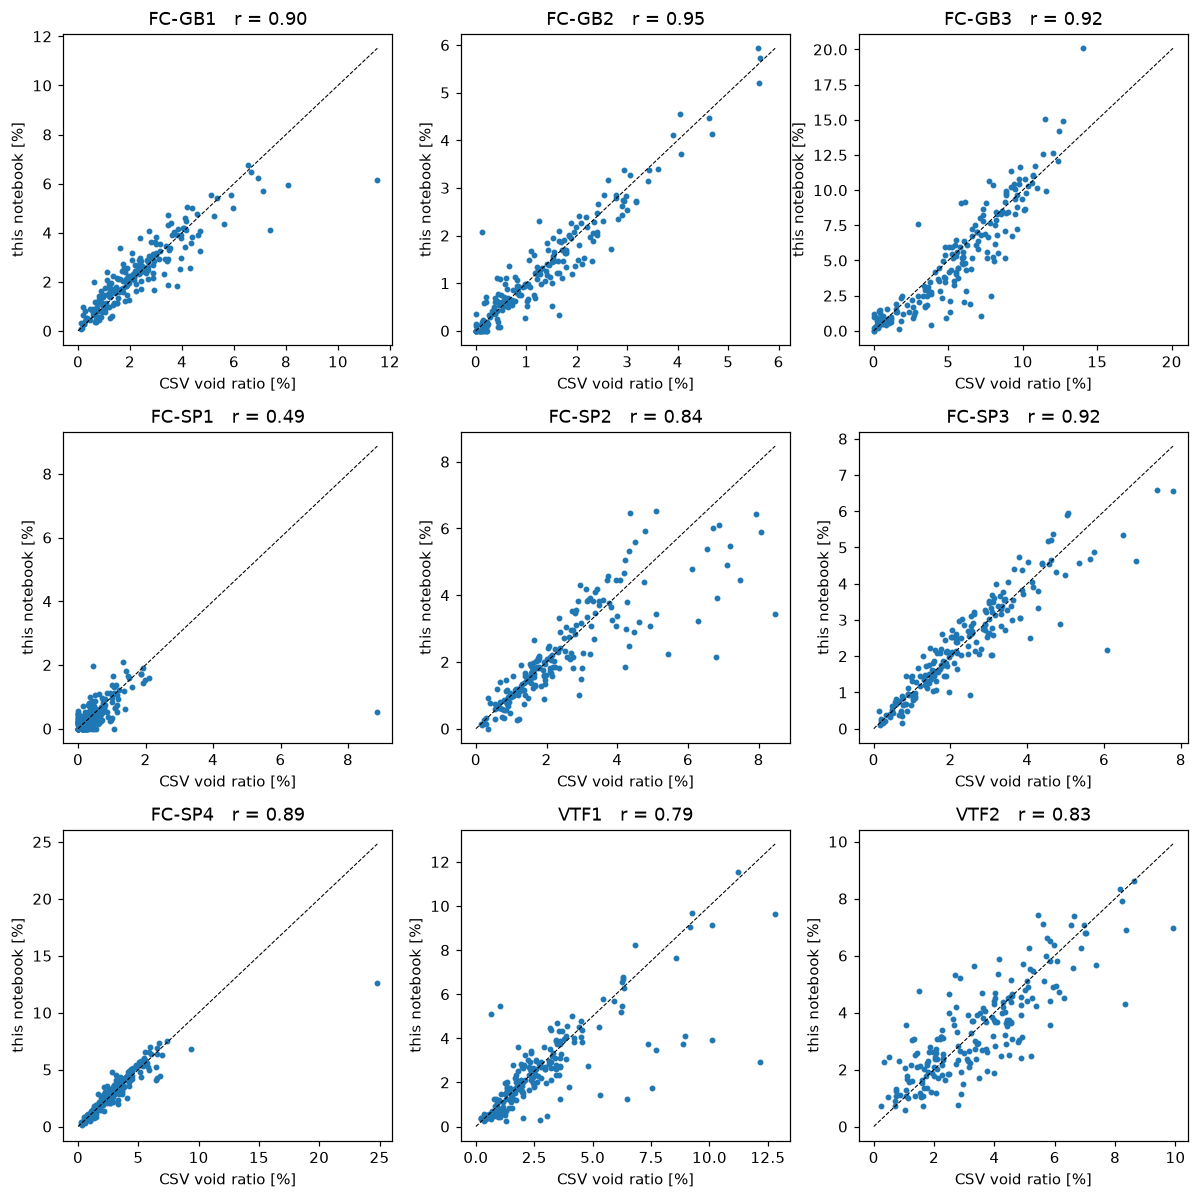

In [14]:
cmp_df = features_df.reset_index().merge(gt_df, on=_KEY, how="left")
cmp_df = cmp_df[(cmp_df.image_missing == 0) & cmp_df.csv_void_ratio.notna()]

summary = cmp_df.groupby("led_type").apply(lambda g: pd.Series({
    "n": len(g),
    "ours_mean_%": 100 * g.void_ratio.mean(),
    "csv_mean_%": 100 * g.csv_void_ratio.mean(),
    "mean_abs_err_%pt": 100 * (g.void_ratio - g.csv_void_ratio).abs().mean(),
    "pearson_r": g.void_ratio.corr(g.csv_void_ratio),
    "spearman_rho": g.void_ratio.corr(g.csv_void_ratio, method="spearman"),
}), include_groups=False)
print(summary.round(2).to_string())
print(f"\nall LEDs: r = {cmp_df.void_ratio.corr(cmp_df.csv_void_ratio):.2f}, "
      f"mean abs. error = {100*(cmp_df.void_ratio - cmp_df.csv_void_ratio).abs().mean():.2f} %-points")

fig, axes = plt.subplots(3, 3, figsize=(11, 11))
for ax, t in zip(axes.flat, LED_TYPES):
    g = cmp_df[cmp_df.led_type == t]
    ax.scatter(100 * g.csv_void_ratio, 100 * g.void_ratio, s=8)
    m = 100 * max(g.csv_void_ratio.max(), g.void_ratio.max())
    ax.plot([0, m], [0, m], "k--", lw=0.7)
    ax.set_title(f"{t}   r = {summary.loc[t, 'pearson_r']:.2f}")
    ax.set_xlabel("CSV void ratio [%]"); ax.set_ylabel("this notebook [%]")
plt.tight_layout(); plt.show()

### Outlined voids for every LED type

Four LEDs per type, from little to most voiding (10th percentile, median, 90th percentile, highest). Red = detected void outline. The title gives our void ratio and the CSV value for the same LED.

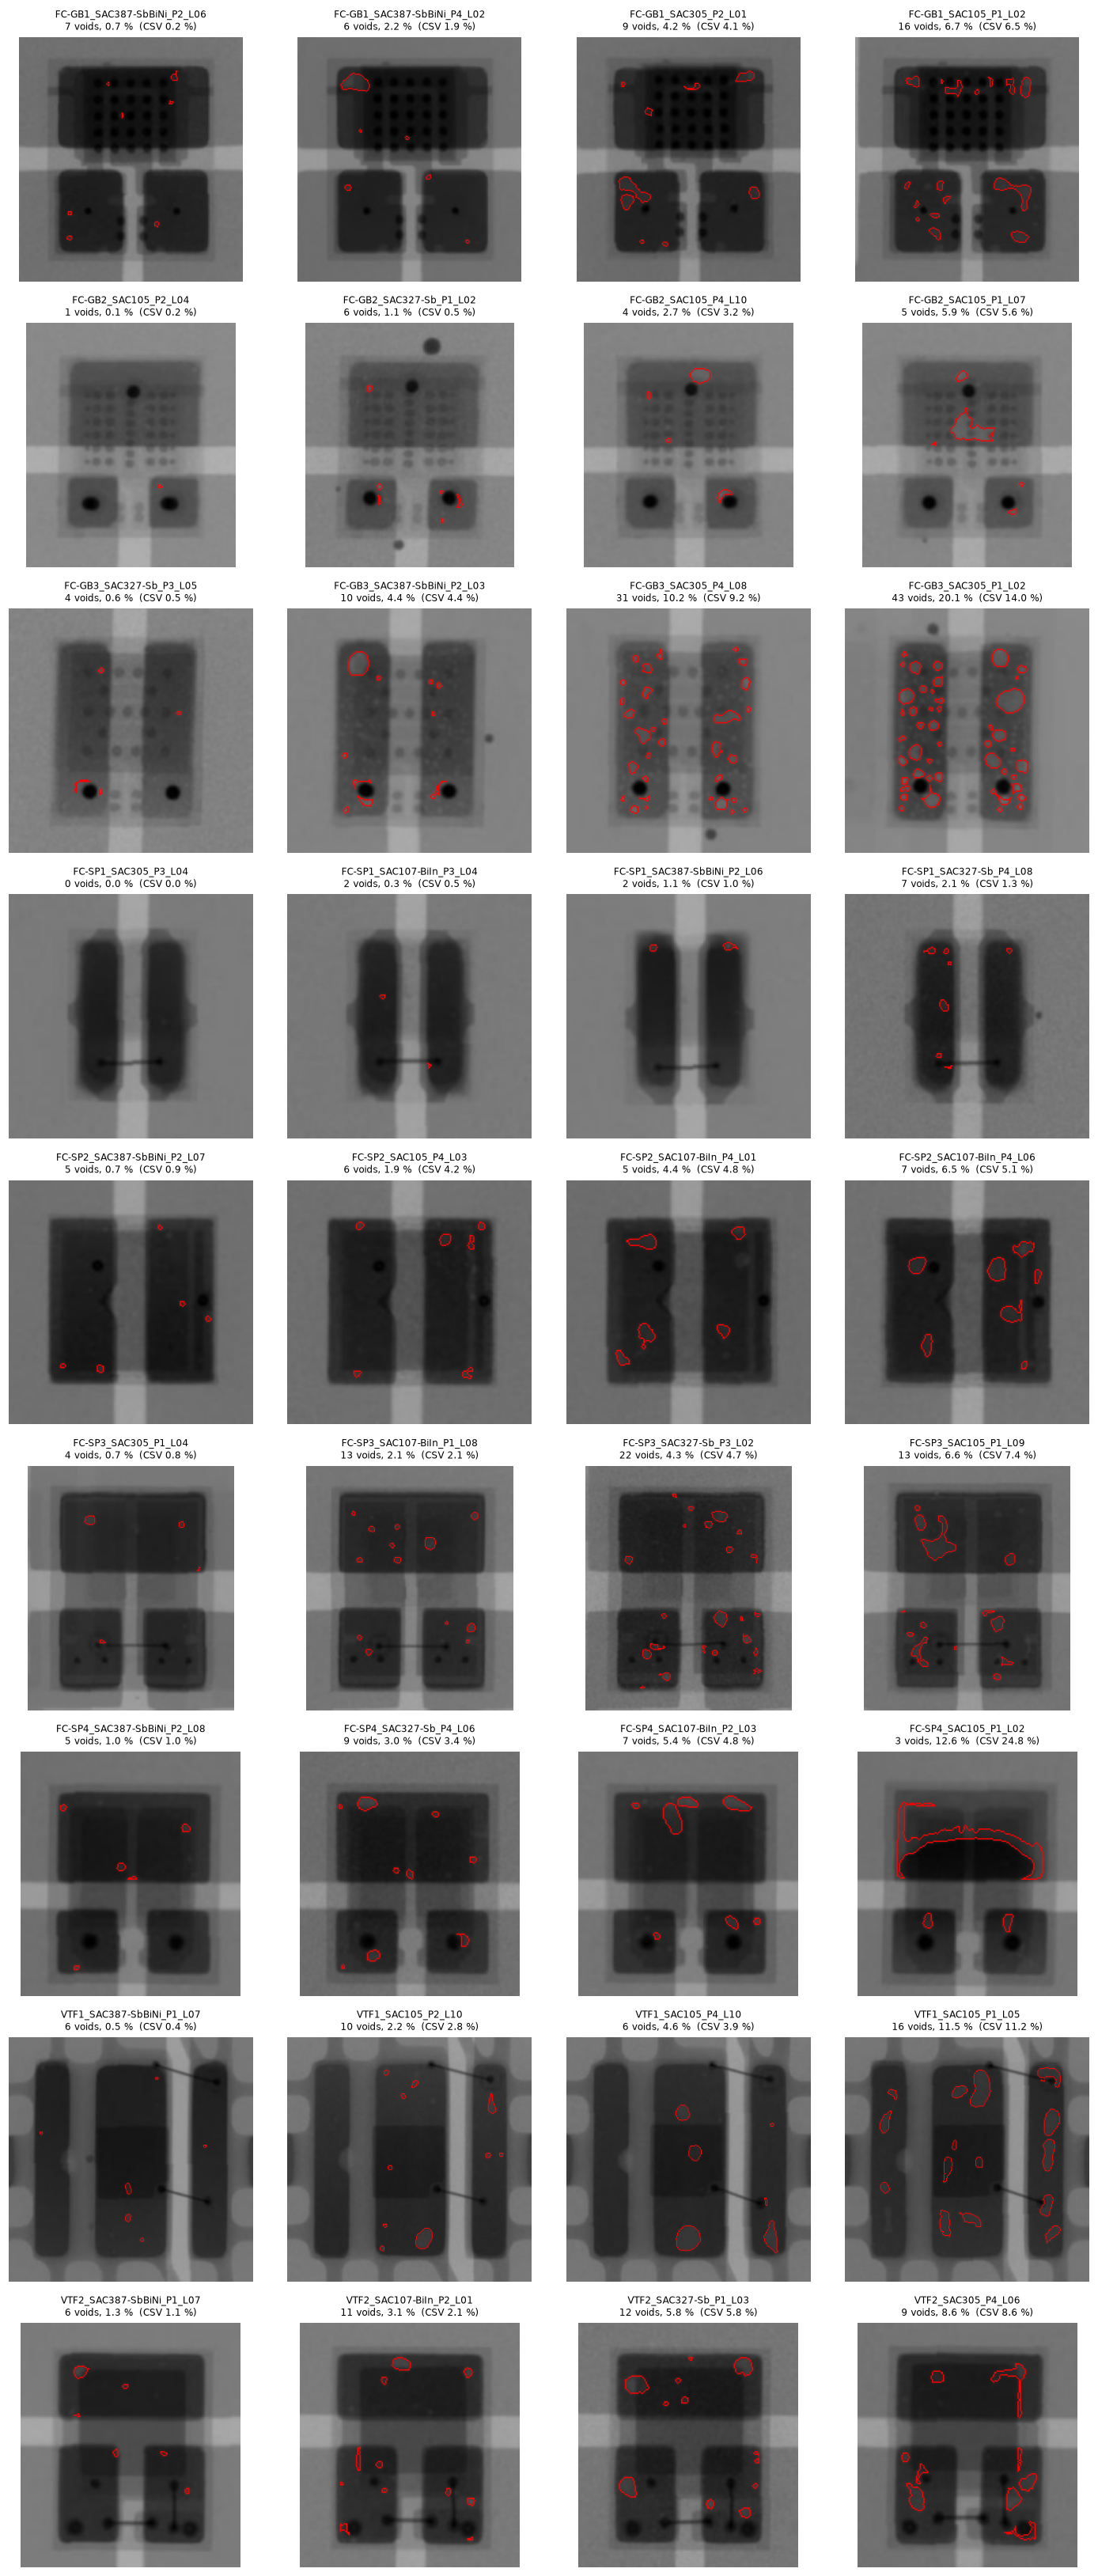

In [15]:
csv_by_unit = features_df.reset_index().merge(gt_df, on=_KEY, how="left").set_index("unit_id")["csv_void_ratio"]

fig, axes = plt.subplots(len(LED_TYPES), 4, figsize=(13, 3.3 * len(LED_TYPES)))
for r, t in enumerate(LED_TYPES):
    for c, s in enumerate(VOID_SAMPLES[t]):
        vis, n = draw_void_outlines(s["img"], s["mask"])
        axes[r, c].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); axes[r, c].axis("off")
        axes[r, c].set_title(f"{s['unit_id']}\n{n} voids, {100*s['void_ratio']:.1f} %  (CSV {100*csv_by_unit.get(s['unit_id'], np.nan):.1f} %)", fontsize=8)
plt.tight_layout(); plt.show()

## 8. Sanity checks

- `has_thermal_pad = 1` for 3-pad LED types, 0 for FC-SP1 / FC-SP2 / FC-GB3
- Total void area fraction distribution — Part I reported ~4% average under vacuum reflow, so this should be heavily right-skewed with a low mean
- Per-paste comparison: Part I Table III shows FC-GB3 has the highest voiding (~5.3%); our thermal-pad void fraction should trend the same way

has_thermal_pad by LED type:
led_type
FC-GB1    1.0
FC-GB2    1.0
FC-GB3    0.0
FC-SP1    0.0
FC-SP2    0.0
FC-SP3    1.0
FC-SP4    1.0
VTF1      1.0
VTF2      1.0

Sample counts by (led_type, paste):
paste     SAC105  SAC107-BiIn  SAC305  SAC327-Sb  SAC387-SbBiNi
led_type                                                       
FC-GB1        40           40      40         40             40
FC-GB2        39           40      40         40             40
FC-GB3        40           40      40         40             40
FC-SP1        40           40      40         40             40
FC-SP2        40           40      40         40             40
FC-SP3        40           40      40         40             40
FC-SP4        40           40      40         40             40
VTF1          40           40      40         40             40
VTF2          40           40      40         40             40


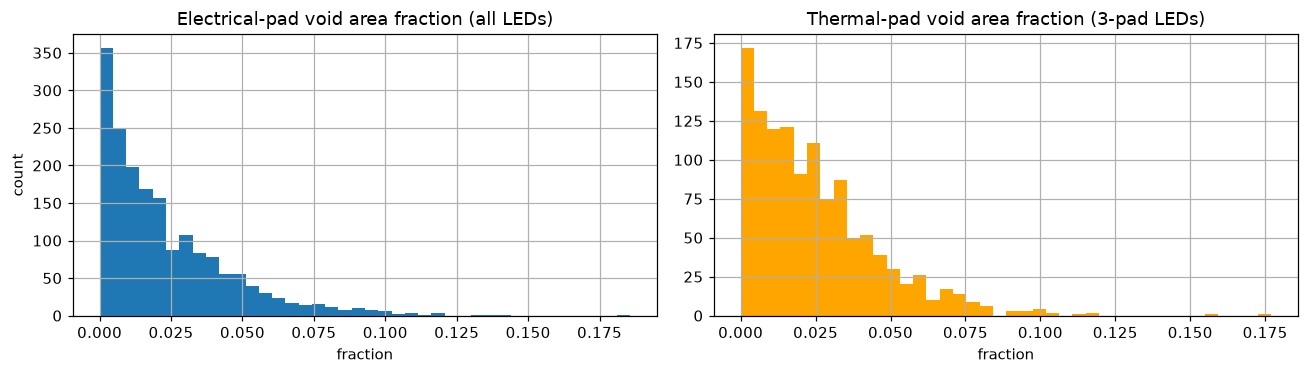


Mean thermal-pad void fraction by LED type (per Part I Table III the pattern should match):
led_type
VTF1      0.032644
FC-SP4    0.032098
VTF2      0.027601
FC-SP3    0.023853
FC-GB1    0.018581
FC-GB2    0.014047
FC-GB3         NaN
FC-SP1         NaN
FC-SP2         NaN


In [16]:
print("has_thermal_pad by LED type:")
print(features_df.groupby("led_type")["has_thermal_pad"].mean().to_string())

print("\nSample counts by (led_type, paste):")
print(features_df.groupby(["led_type", "paste"]).size().unstack(fill_value=0))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
features_df["electrical_mean_void_area_frac"].hist(bins=40, ax=ax[0])
ax[0].set_title("Electrical-pad void area fraction (all LEDs)")
ax[0].set_xlabel("fraction"); ax[0].set_ylabel("count")
features_df["thermal_void_area_frac"].dropna().hist(bins=40, ax=ax[1], color="orange")
ax[1].set_title("Thermal-pad void area fraction (3-pad LEDs)")
ax[1].set_xlabel("fraction")
plt.tight_layout(); plt.show()

print("\nMean thermal-pad void fraction by LED type (per Part I Table III the pattern should match):")
print(features_df.groupby("led_type")["thermal_void_area_frac"].mean().sort_values(ascending=False).to_string())

## 9. Save feature matrix

In [17]:
out_dir = Path("../data/processed")
out_dir.mkdir(parents=True, exist_ok=True)
out_csv = out_dir / "spatial_void_features_improved.csv"
features_df.to_csv(out_csv)
print(f"Wrote {out_csv}  ({out_csv.stat().st_size} bytes, {len(features_df)} rows)")

Wrote ..\data\processed\spatial_void_features_improved.csv  (2508636 bytes, 1799 rows)


## 10. Next steps

1. **Join target.** Merge `features_df` with `rth_start_end.csv` on `unit_id`, compute `TSC_fail` using Part II's FailCT(RI in R_th) ≡ 20%, and discretize to Class 1 / 2 / 3.
2. **Baseline vs. spatial Random Forest (per §5.3 of the proposal).**
   - Baseline features: `led_type` one-hot + `paste` one-hot + total void ratio (use `electrical_mean_void_area_frac` or add a joint-wide one).
   - Spatial features: baseline + all `thermal_*` and `electrical_mean_*` columns.
   - Cross-validated per-class F1; test whether spatial model improves significantly over baseline.
3. **Void threshold.** `VOID_T` is calibrated per LED type against `Xray Void Ratio.csv` (see `calibrate_threshold`). Re-calibrate if the registration or the fit is changed.
4. **(Optional) Per-pad electrical features.** For 3-pad LEDs with two electrical pads, you currently average them. If asymmetry matters (e.g. voids under cathode worse than under anode), replace `electrical_mean_*` with `electrical_a_*` / `electrical_b_*` indexed by pad position.